# Resultados de la etapa actual

Este notebook reúne todo lo probado desde el 20 de octubre: por qué el modelo de referencia (E57) no aprendía, cómo se corrigió y qué rendimiento tiene la nueva receta. Las cifras se leen de las salidas guardadas en `reports/`; no hace falta abrir ningún CSV ni JSON. Para actualizarlo con resultados nuevos: `python -m src.cuaderno_resultados`.

### Cómo se mide

Cada fold docente (unas 219 pacientes) hace de **exterior**. Con el resto se entrena: el 80 % es **FIT** (unas 702 pacientes, con las que aprende la red) y el 20 % es la **validación interna** (unas 176), que elige la época y el umbral. Después, y una sola vez, se evalúan las pacientes exteriores. La probabilidad de una paciente es la media de las de sus cortes.

**Qué AUC mirar.** La cifra principal es la **AUC exterior**: pacientes que el modelo no vio, con decisiones tomadas sin mirarlas. El pico de validación es optimista, porque se elige la mejor de muchas épocas sobre las mismas pacientes. Con unas 219 pacientes, el error típico del AUC de un fold es ≈ 0,043: diferencias menores de 0,05 entre recetas en un solo fold no se distinguen del azar.

**Cómo leer las gráficas de cada ejecución.**
- *Tres gráficas*: la pérdida y el AUC de train e interna en cada época. Si train sube y la interna se queda quieta o baja, la red está memorizando. A la derecha, el AUC en la época elegida de train, interna y exterior; la diferencia train − exterior mide cuánto se pierde con pacientes nuevas.
- *Panel de resultados*: curva ROC y precisión-recall (no dependen del umbral), la matriz de confusión con el umbral interno, la calibración (¿las probabilidades significan lo que dicen?), cómo se reparten las probabilidades de cada clase y las métricas de la decisión.

### Índice

1. [La red](#red)
2. [Resumen](#resumen)
3. [Por qué E57 no aprendía (N01)](#diagnostico)
4. [P01: lotes con más pacientes](#p01)
5. [P02: aumento geométrico sincronizado](#p02)
6. [P02 en 5 folds: BCE normal frente a ponderada](#cv)
7. [Modelo de entrega y test](#entrega)
8. [E57 como referencia](#e57)
9. [Qué más se probó después de P02](#despues)
10. [N01 en 5 folds: la receta de E57 con validación cruzada](#n01cv)

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams['figure.max_open_warning'] = 0  # el notebook muestra muchas figuras a propósito
from IPython.display import Image, Markdown, display
from src import cuaderno_resultados as R

<a id="red"></a>
## 1. La red

Todos los experimentos de esta etapa usan **la misma CNN**, la de E57, creada desde cero: lo que cambia es cómo se entrena. Tiene **298.161 parámetros**. Recibe las tres fases de un corte y las convierte en PRE, EARLY − PRE y LATE − EARLY (restas fijas, sin parámetros), para que el realce del contraste llegue explícito. Después hay cuatro bloques de dos convoluciones 3×3 (16, 32, 64 y 128 canales), cada una con BatchNorm y ReLU, y una reducción MaxPool 2×2 en cada bloque: la imagen pasa de 256 × 256 a 16 × 16 píxeles. La media espacial global resume cada canal en un número (128 en total) y una cabeza 128 → 32 → 1, con ReLU y dropout 0,3, da el logit. El campo receptivo de cada neurona final es de 106 × 106 píxeles.

En entrenamiento se promedian las 128 características de los cortes de cada paciente antes de la cabeza; en evaluación, se predice cada corte y se promedian sus probabilidades. La ficha con todas las capas está en [experimentos/E57_patient_feature_mean_mac](../experimentos/E57_patient_feature_mean_mac/README.md).

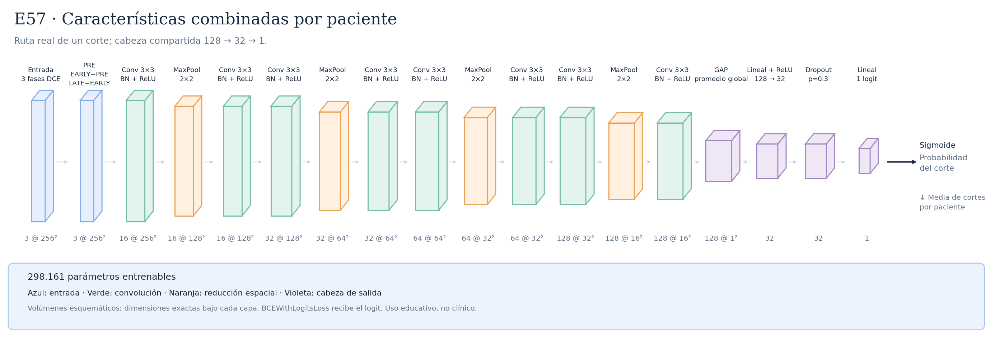

In [2]:
display(Image(filename=str(R.ROOT/'E57/ARQUITECTURA.png'), width=1000))

<a id="resumen"></a>
## 2. Resumen

Una fila por ejecución completa de la etapa. *AUC train* y *AUC interna* son de la época elegida; *AUC exterior* es la cifra que cuenta. *Por corte* es el AUC cuando se puntúa cada corte por separado, que es lo que hará la web en la defensa (un corte por paciente).

In [3]:
R.tabla_resumen()

Experimento,Qué cambia,Pérdida,Fold,Plataforma,Época elegida,AUC train (FIT),AUC validación interna,AUC exterior,AUC exterior por corte
N01,Receta E57: 2 pacientes por lote,normal,0,Mac,2 de 12,"0,505","0,572","0,617","0,602"
N01,Receta E57: 2 pacientes por lote,normal,1,Mac,6 de 16,"0,561","0,611","0,494","0,500"
N01,Receta E57: 2 pacientes por lote,normal,2,Mac,13 de 23,"0,529","0,618","0,542","0,549"
N01,Receta E57: 2 pacientes por lote,normal,3,Mac,6 de 16,"0,585","0,577","0,472","0,470"
N01,Receta E57: 2 pacientes por lote,normal,4,Mac,6 de 16,"0,541","0,596","0,445","0,452"
N01,Receta E57: 2 pacientes por lote,ponderada,0,Mac,11 de 21,"0,548","0,650","0,547","0,545"
P01,10 pacientes × 2 cortes por lote,normal,0,Mac,6 de 16,"0,593","0,611","0,570","0,569"
P02,P01 + aumento geométrico sincronizado,normal,0,Mac,14 de 24,"0,665","0,625","0,535","0,528"
P02,P01 + aumento geométrico sincronizado,normal,0,GPU,9 de 19,"0,646","0,650","0,561","0,556"
P02,P01 + aumento geométrico sincronizado,normal,1,GPU,19 de 29,"0,681","0,643","0,543","0,541"


<a id="diagnostico"></a>
## 3. Por qué E57 no aprendía (N01)

**Qué se observó.** En los 5 folds de E57 la pérdida de entrenamiento se quedó entre 0,59 y 0,63, cuando un predictor que siempre responde la prevalencia (29,3 % de pCR) obtiene 0,605. Sus probabilidades casi no variaban entre pacientes y el AUC sobre sus propias pacientes de entrenamiento era de 0,50–0,56. N01, la comparación BCE normal frente a ponderada con la misma receta, lo confirmó: con la ponderada la pérdida terminó en 0,979, exactamente el óptimo de un predictor constante con ese peso.

**Qué significa.** Los picos de validación de E57 (0,670 en el fold 0) eran un salto aislado dentro de una curva plana, del tamaño que produce el azar al elegir la mejor de unas 20 épocas. Esto explica también por qué ~200 experimentos de arquitectura no se distinguían: comparaban redes que apenas aprendían, con un fold de 219 pacientes.

**Hipótesis.** E57 entrenaba con lotes de solo 2 pacientes. BatchNorm normaliza cada canal con la media del lote: con dos pacientes, sus características quedan forzadas a compensarse y la red solo puede aprender diferencias entre esas dos; en cerca del 59 % de los lotes ambas tienen la misma etiqueta.

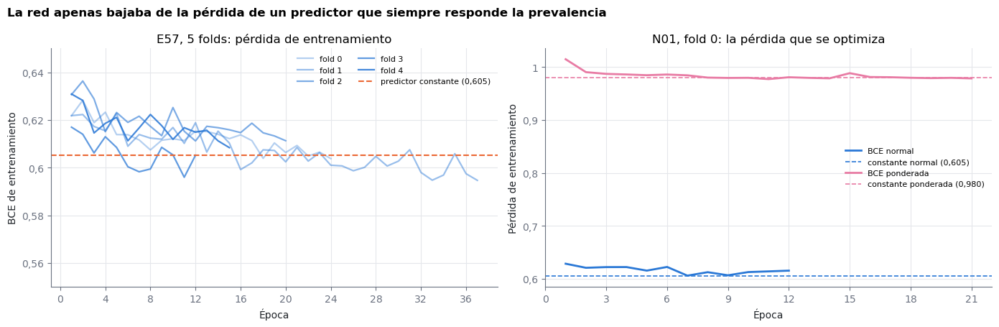

In [4]:
R.fig_colapso()

Detalle de las ejecuciones de N01 (el fold 0 con las dos pérdidas; los folds 1–4 de la BCE normal se añadieron después, ver sección 10). Fíjate en la tabla de épocas: el AUC de train no se separa de 0,5 y la pérdida apenas se mueve.

### N01 · BCE normal · fold 0 · 12 épocas · checkpoint de época 2

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [5]:
R.tabla_epocas(R.N01, 'normal', 0)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,LR,Segundos
1,0.628659,0.690850,0.653320,0.516383,0.571650,"0,001",81
2,0.620948,0.617854,0.602592,0.505216,0.572115,"0,001",83
3,0.622246,0.623107,0.621467,0.510854,0.495658,"0,001",82
4,0.622312,0.602788,0.608032,0.568069,0.533964,"0,001",81
5,0.615600,0.612164,0.603113,0.505334,0.566532,"0,001",80
6,0.622548,0.607581,0.604951,0.509405,0.504653,"0,001",81
7,0.606115,0.607118,0.607160,0.523831,0.489144,"0,0005",81
8,0.612640,0.605899,0.606600,0.529430,0.510081,"0,0005",82
9,0.606773,0.621224,0.624300,0.471549,0.474256,"0,0005",82
10,0.612874,0.607072,0.611998,0.534871,0.509460,"0,0005",80


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

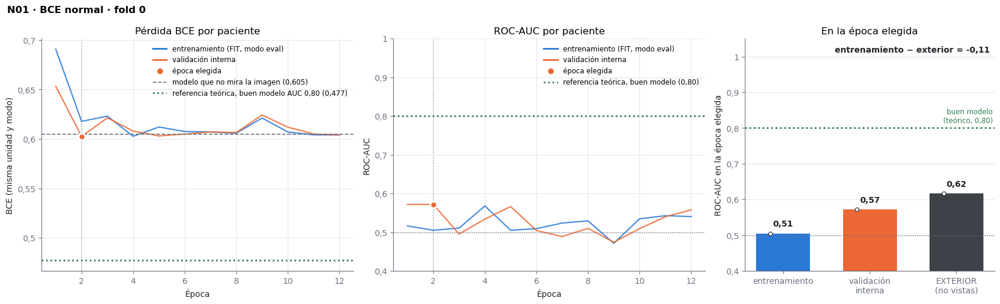

In [6]:
R.fig_tres(R.N01, 'normal', 0, 'N01')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

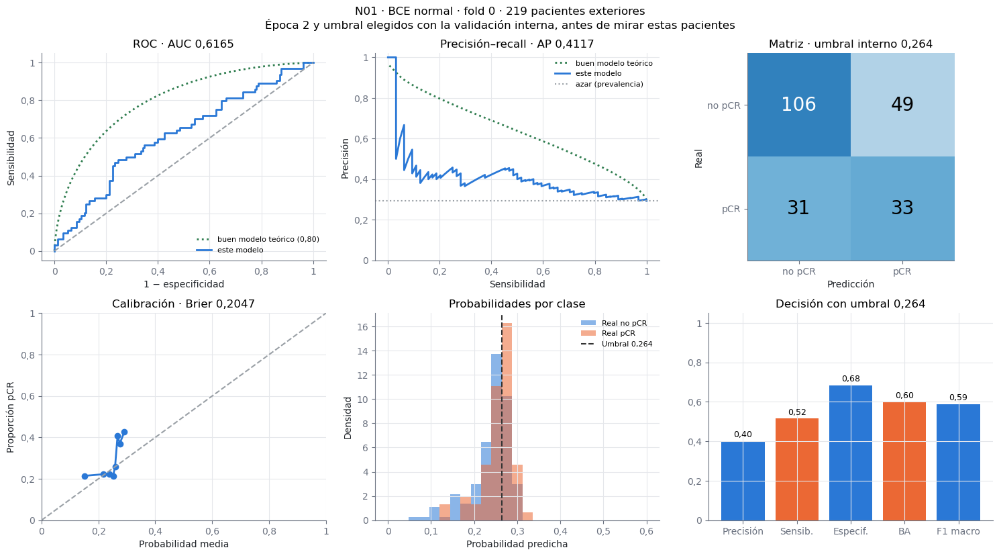

In [7]:
R.fig_resultados(R.N01, 'normal', 0, 'N01')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

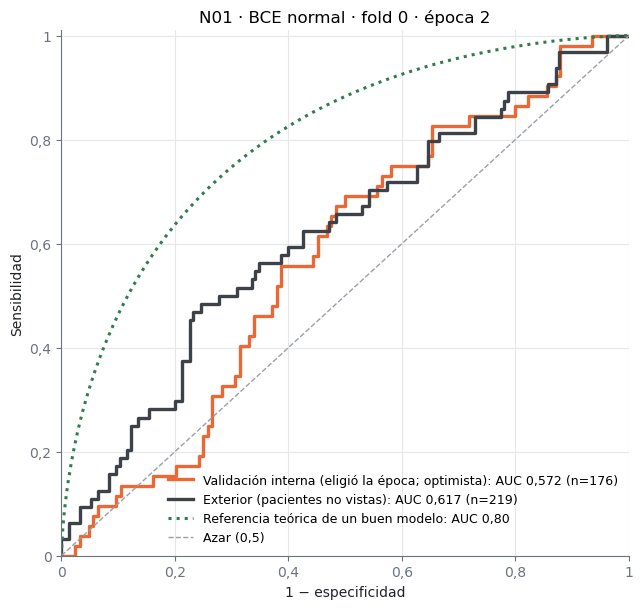

In [8]:
R.fig_roc_dos(R.N01, 'normal', 0, 'N01')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

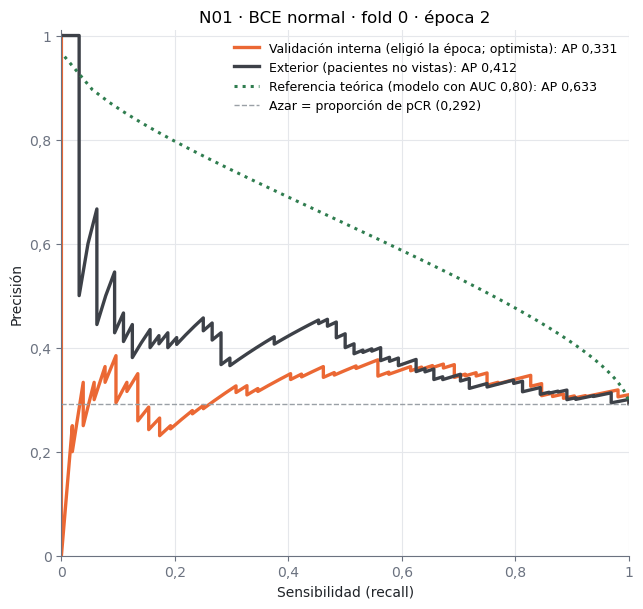

In [9]:
R.fig_pr_dos(R.N01, 'normal', 0, 'N01')

In [10]:
R.tabla_umbrales(R.N01, 'normal', 0)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,264",106,49,31,33,"0,516","0,684","0,402","0,600"
"0,325 (el de E57): 0,325",155,0,64,0,"0,000","1,000",—,"0,500"
"0,5: 0,500",155,0,64,0,"0,000","1,000",—,"0,500"


### N01 · BCE normal · fold 1 · 16 épocas · checkpoint de época 6

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [11]:
R.tabla_epocas(R.N01, 'normal', 1)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,LR,Segundos
1,0.635896,0.627571,0.624225,0.469149,0.494572,"0,001",83
2,0.615546,0.609506,0.609827,0.499864,0.486042,"0,001",80
3,0.626320,0.614450,0.614386,0.526992,0.505428,"0,001",82
4,0.625748,0.605937,0.607066,0.539571,0.504342,"0,001",82
5,0.616081,0.612213,0.617424,0.513207,0.439516,"0,001",83
6,0.625771,0.608968,0.604348,0.561342,0.610887,"0,001",84
7,0.619000,0.604108,0.600325,0.571103,0.569479,"0,001",81
8,0.611455,0.606711,0.603506,0.560291,0.571185,"0,001",82
9,0.622292,0.602633,0.604385,0.578568,0.579249,"0,001",82
10,0.614363,0.602454,0.605040,0.585390,0.556064,"0,001",82


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

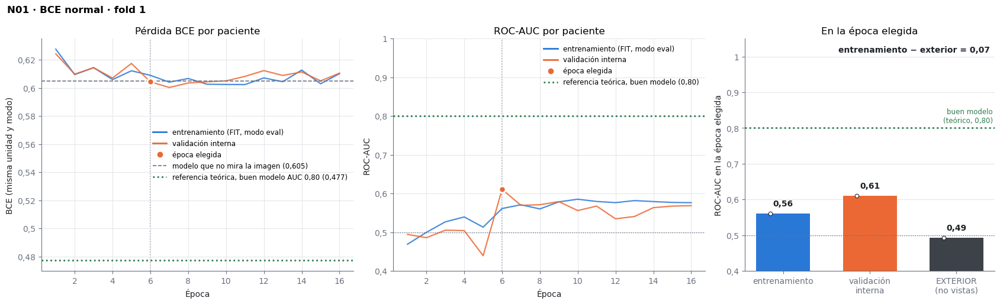

In [12]:
R.fig_tres(R.N01, 'normal', 1, 'N01')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

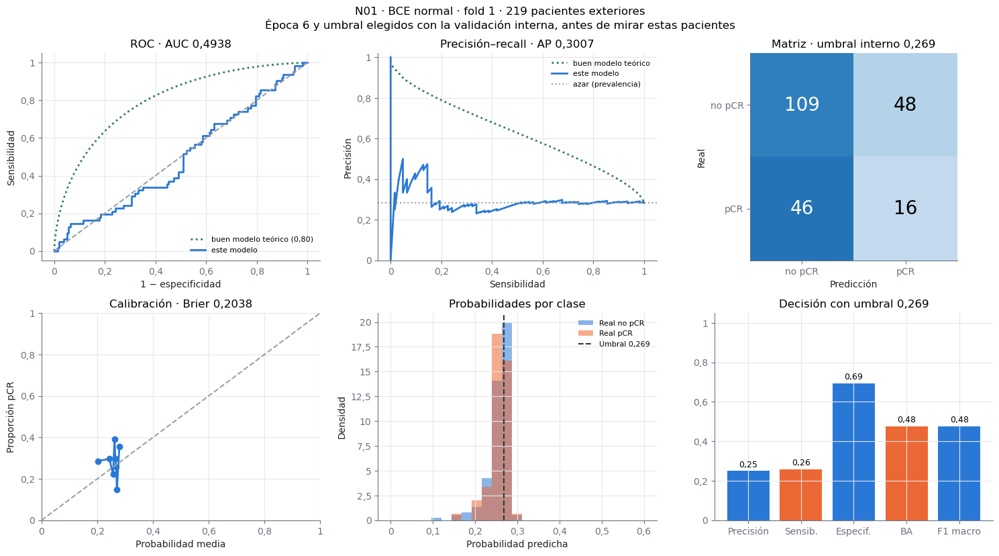

In [13]:
R.fig_resultados(R.N01, 'normal', 1, 'N01')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

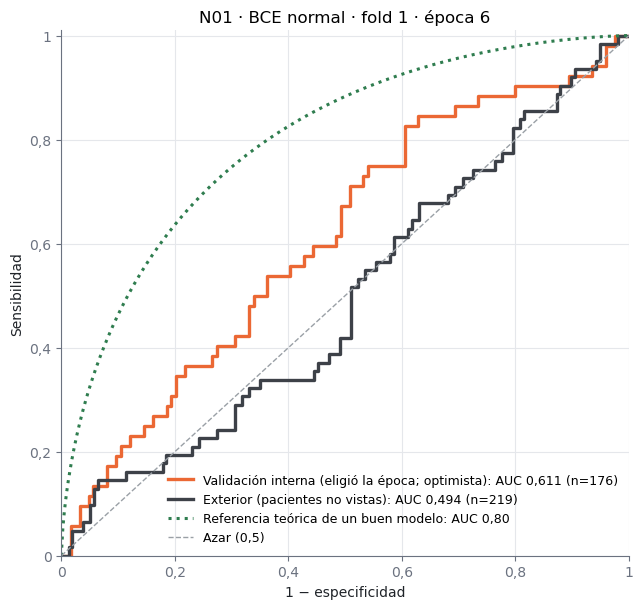

In [14]:
R.fig_roc_dos(R.N01, 'normal', 1, 'N01')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

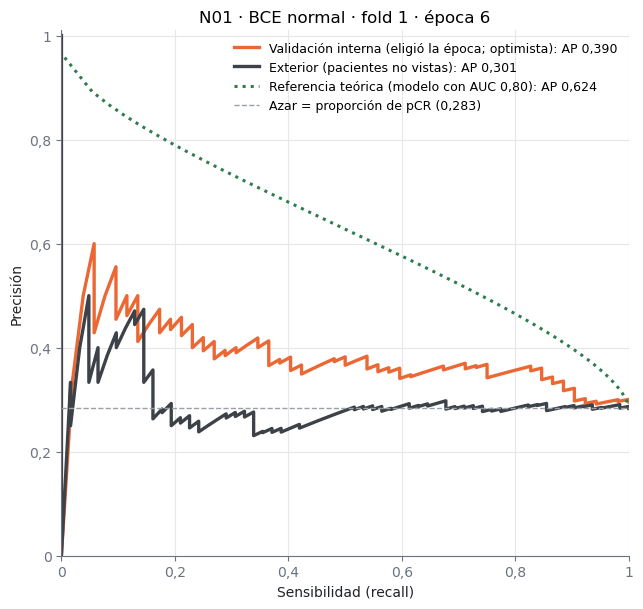

In [15]:
R.fig_pr_dos(R.N01, 'normal', 1, 'N01')

In [16]:
R.tabla_umbrales(R.N01, 'normal', 1)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,269",109,48,46,16,"0,258","0,694","0,250","0,476"
"0,325 (el de E57): 0,325",157,0,62,0,"0,000","1,000",—,"0,500"
"0,5: 0,500",157,0,62,0,"0,000","1,000",—,"0,500"


### N01 · BCE normal · fold 2 · 23 épocas · checkpoint de época 13

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [17]:
R.tabla_epocas(R.N01, 'normal', 2)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,LR,Segundos
1,0.640421,0.631389,0.654313,0.534410,0.473539,"0,001",82
2,0.620052,0.613153,0.634526,0.560595,0.480595,"0,001",81
3,0.626460,0.663602,0.654553,0.495073,0.502071,"0,001",80
4,0.625640,0.623005,0.632901,0.526603,0.444240,"0,001",82
5,0.621895,0.609899,0.615963,0.545670,0.440712,"0,001",83
6,0.612409,0.622051,0.627156,0.531316,0.418009,"0,001",85
7,0.613480,0.618176,0.616092,0.569615,0.583678,"0,001",81
8,0.622630,0.607370,0.611033,0.568248,0.547170,"0,001",82
9,0.613036,0.607369,0.622189,0.559800,0.481976,"0,001",84
10,0.611152,0.630443,0.607057,0.543478,0.560209,"0,001",83


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

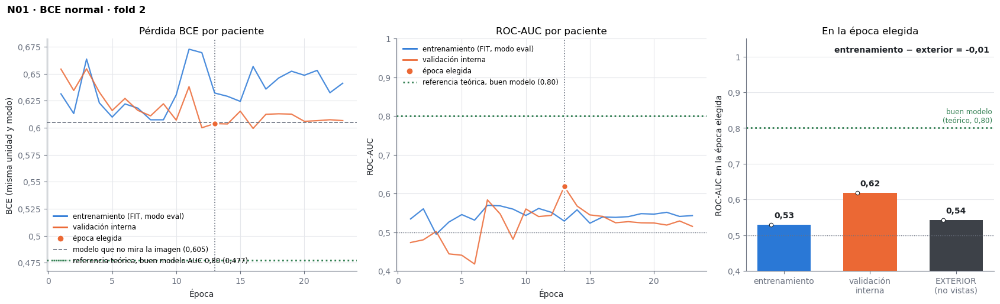

In [18]:
R.fig_tres(R.N01, 'normal', 2, 'N01')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

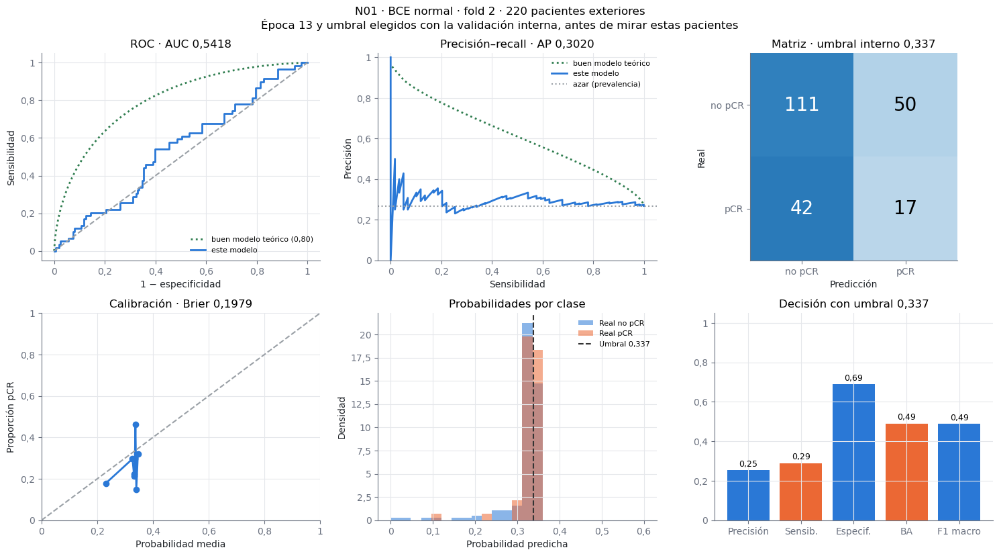

In [19]:
R.fig_resultados(R.N01, 'normal', 2, 'N01')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

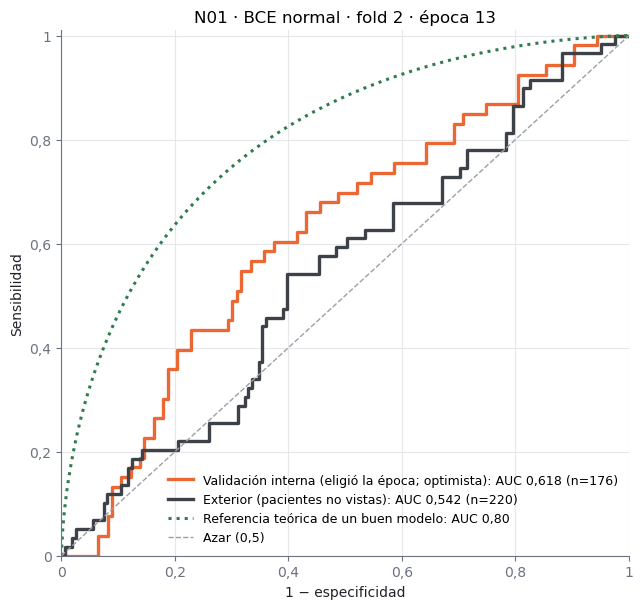

In [20]:
R.fig_roc_dos(R.N01, 'normal', 2, 'N01')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

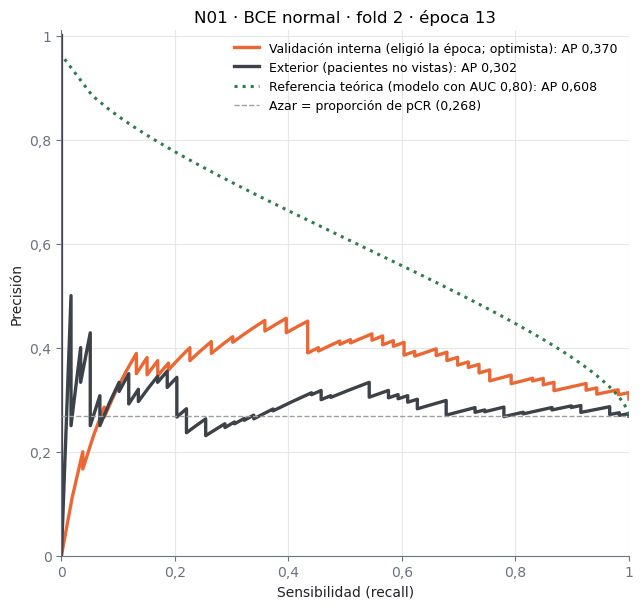

In [21]:
R.fig_pr_dos(R.N01, 'normal', 2, 'N01')

In [22]:
R.tabla_umbrales(R.N01, 'normal', 2)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,337",111,50,42,17,"0,288","0,689","0,254","0,489"
"0,325 (el de E57): 0,325",30,131,7,52,"0,881","0,186","0,284","0,534"
"0,5: 0,500",161,0,59,0,"0,000","1,000",—,"0,500"


### N01 · BCE normal · fold 3 · 16 épocas · checkpoint de época 6

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [23]:
R.tabla_epocas(R.N01, 'normal', 3)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,LR,Segundos
1,0.626473,0.595806,0.617089,0.544658,0.417302,"0,001",80
2,0.626749,0.609524,0.610742,0.473723,0.452698,"0,001",82
3,0.609199,0.609822,0.613177,0.488005,0.439365,"0,001",84
4,0.611678,0.608541,0.616086,0.469976,0.432857,"0,001",85
5,0.595719,0.592969,0.603803,0.561518,0.494444,"0,001",86
6,0.609009,0.590236,0.593577,0.584683,0.576984,"0,001",84
7,0.603391,0.584021,0.593884,0.596064,0.544444,"0,001",83
8,0.596317,0.586469,0.595655,0.591713,0.542540,"0,001",83
9,0.602328,0.586249,0.596496,0.600324,0.494603,"0,001",85
10,0.602246,0.588101,0.597233,0.615371,0.495238,"0,001",84


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

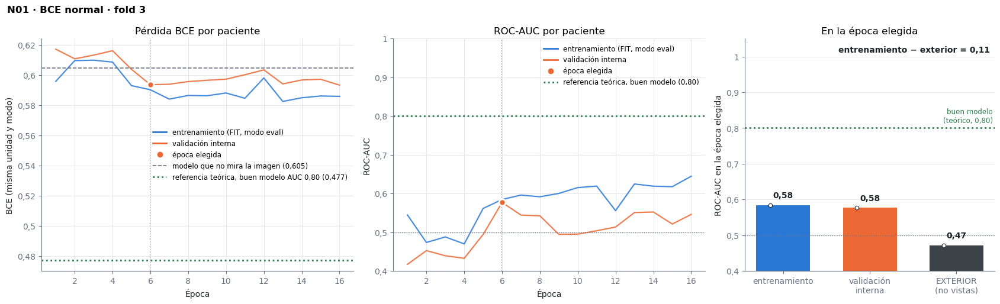

In [24]:
R.fig_tres(R.N01, 'normal', 3, 'N01')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

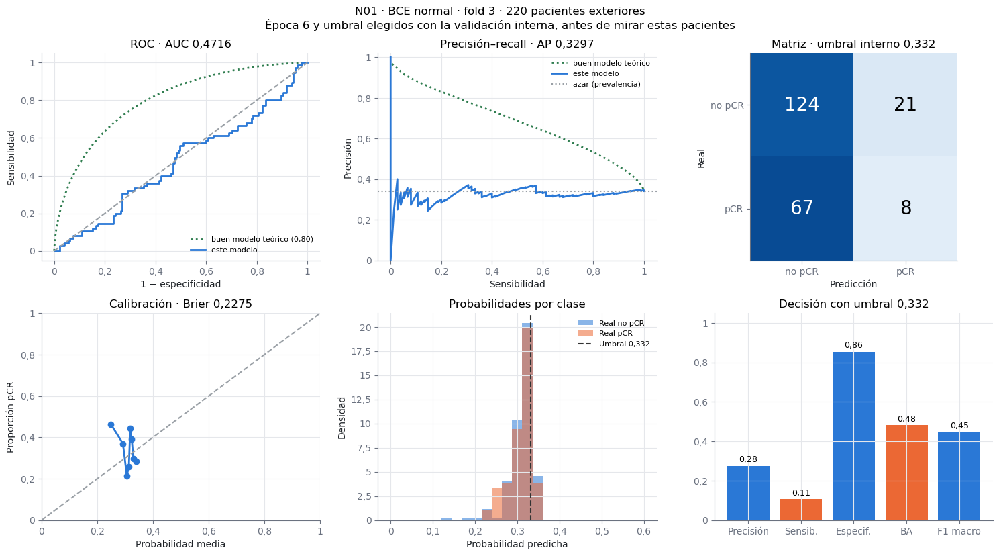

In [25]:
R.fig_resultados(R.N01, 'normal', 3, 'N01')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

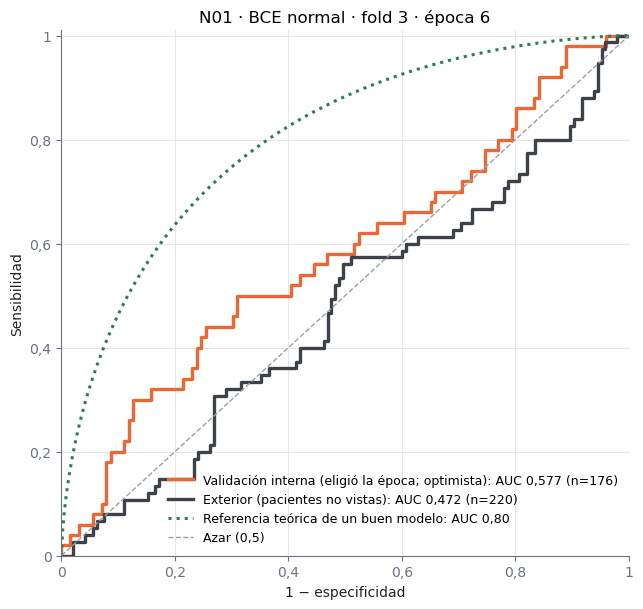

In [26]:
R.fig_roc_dos(R.N01, 'normal', 3, 'N01')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

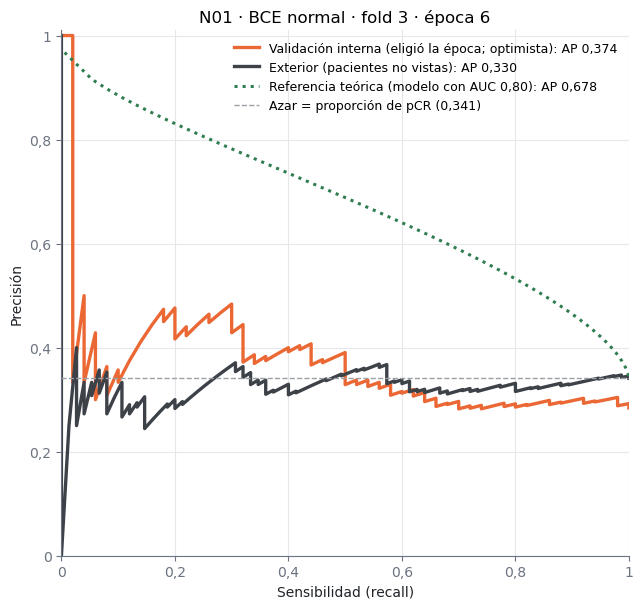

In [27]:
R.fig_pr_dos(R.N01, 'normal', 3, 'N01')

In [28]:
R.tabla_umbrales(R.N01, 'normal', 3)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,332",124,21,67,8,"0,107","0,855","0,276","0,481"
"0,325 (el de E57): 0,325",104,41,52,23,"0,307","0,717","0,359","0,512"
"0,5: 0,500",145,0,75,0,"0,000","1,000",—,"0,500"


### N01 · BCE normal · fold 4 · 16 épocas · checkpoint de época 6

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [29]:
R.tabla_epocas(R.N01, 'normal', 4)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,LR,Segundos
1,0.638436,0.625649,0.666517,0.567658,0.448511,"0,001",80
2,0.624036,0.616622,0.638464,0.546675,0.458127,"0,001",81
3,0.626442,0.609404,0.610539,0.572544,0.488524,"0,001",83
4,0.624728,0.604353,0.610254,0.557274,0.500775,"0,001",83
5,0.616443,0.610470,0.608896,0.542345,0.559088,"0,001",82
6,0.624609,0.607930,0.604149,0.540593,0.596464,"0,001",83
7,0.620325,0.607035,0.605322,0.553439,0.519231,"0,001",83
8,0.612333,0.610049,0.604783,0.540729,0.533499,"0,001",86
9,0.618228,0.609167,0.605612,0.555736,0.569789,"0,001",86
10,0.620309,0.606172,0.603794,0.561478,0.550558,"0,001",85


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

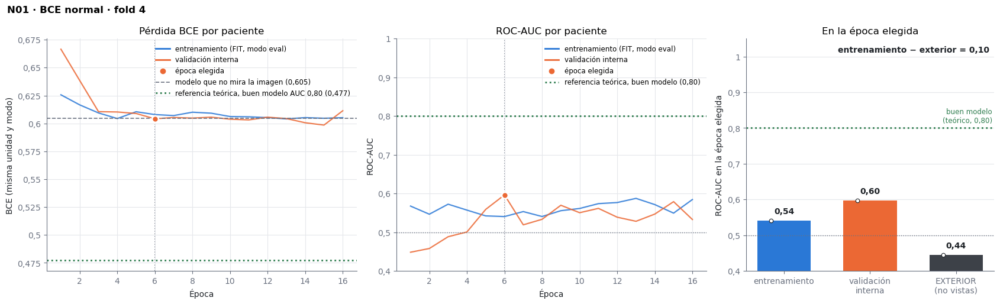

In [30]:
R.fig_tres(R.N01, 'normal', 4, 'N01')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

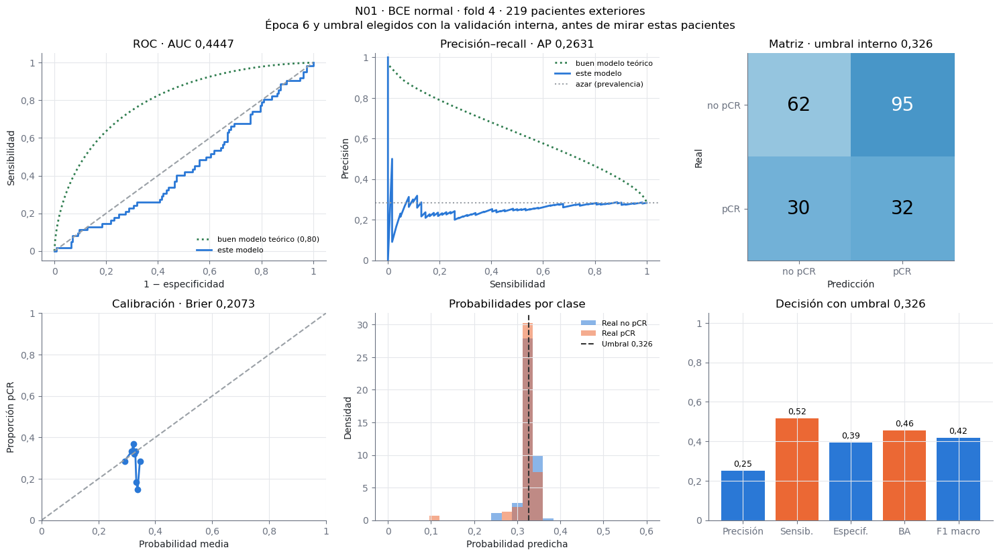

In [31]:
R.fig_resultados(R.N01, 'normal', 4, 'N01')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

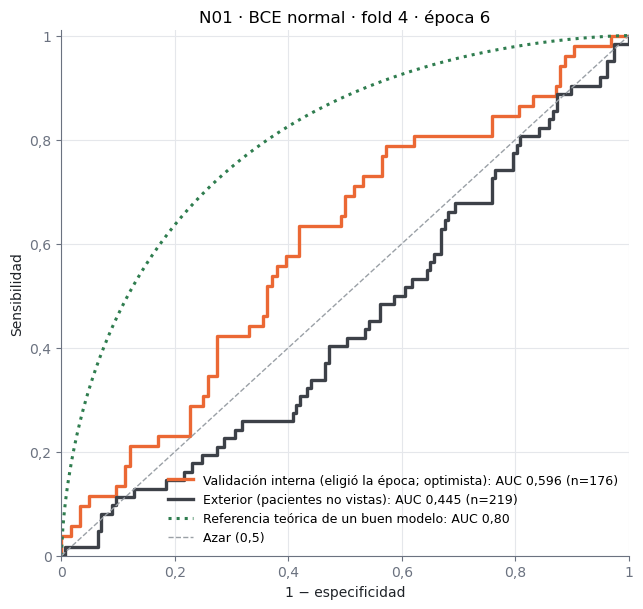

In [32]:
R.fig_roc_dos(R.N01, 'normal', 4, 'N01')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

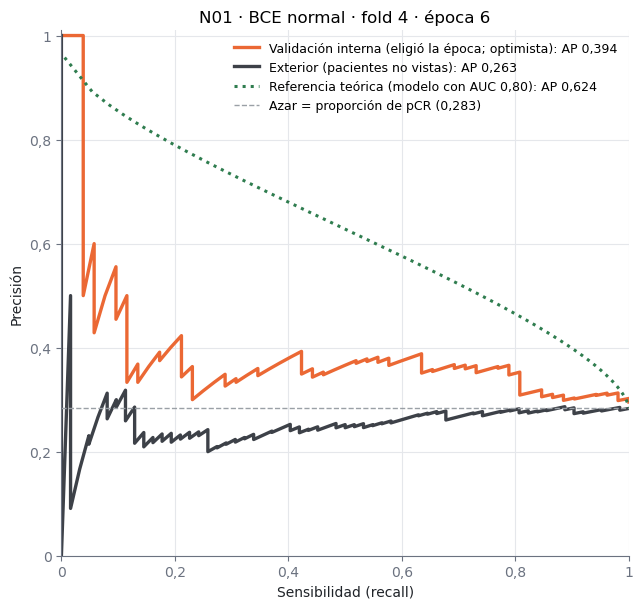

In [33]:
R.fig_pr_dos(R.N01, 'normal', 4, 'N01')

In [34]:
R.tabla_umbrales(R.N01, 'normal', 4)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,326",62,95,30,32,"0,516","0,395","0,252","0,456"
"0,325 (el de E57): 0,325",54,103,26,36,"0,581","0,344","0,259","0,462"
"0,5: 0,500",157,0,62,0,"0,000","1,000",—,"0,500"


### N01 · BCE ponderada · fold 0 · 21 épocas · checkpoint de época 11

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [35]:
R.tabla_epocas(R.N01, 'weighted', 0)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,LR,Segundos
1,1.014848,0.611288,0.617764,0.533853,0.504032,"0,001",81
2,0.990452,0.651503,0.647030,0.519740,0.567308,"0,001",82
3,0.987199,0.660509,0.659295,0.547643,0.634460,"0,001",83
4,0.986087,0.692624,0.689235,0.538443,0.613058,"0,001",85
5,0.984715,0.704603,0.704895,0.527922,0.508375,"0,001",84
6,0.985984,0.671872,0.671719,0.534127,0.575372,"0,001",83
7,0.984488,0.672568,0.673417,0.547291,0.558778,"0,001",89
8,0.980175,0.677530,0.679632,0.540753,0.544665,"0,0005",86
9,0.979547,0.681454,0.682160,0.552400,0.555056,"0,0005",86
10,0.979762,0.684813,0.686375,0.552233,0.544045,"0,0005",85


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

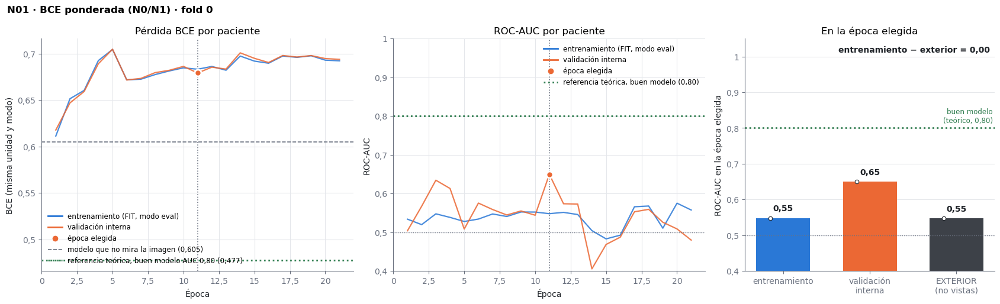

In [36]:
R.fig_tres(R.N01, 'weighted', 0, 'N01')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

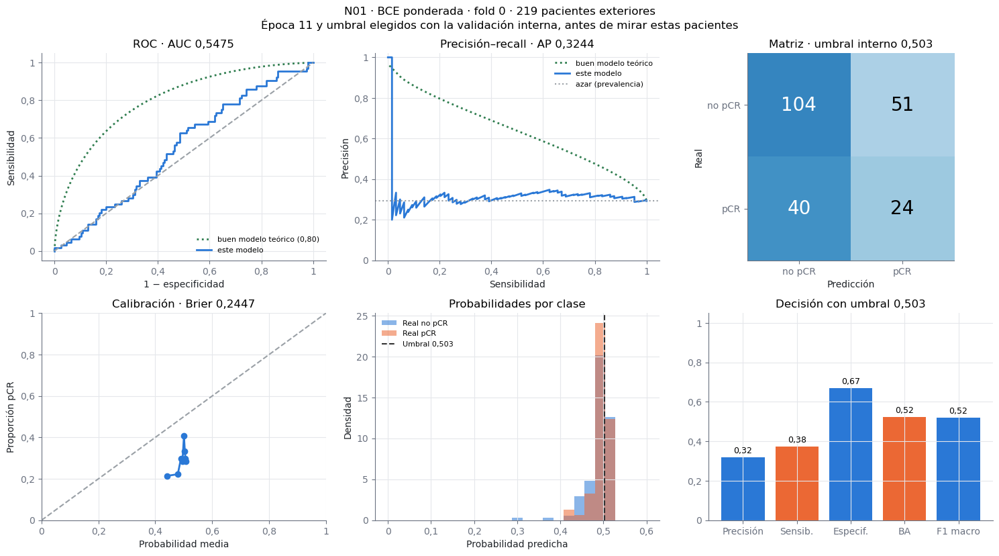

In [37]:
R.fig_resultados(R.N01, 'weighted', 0, 'N01')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

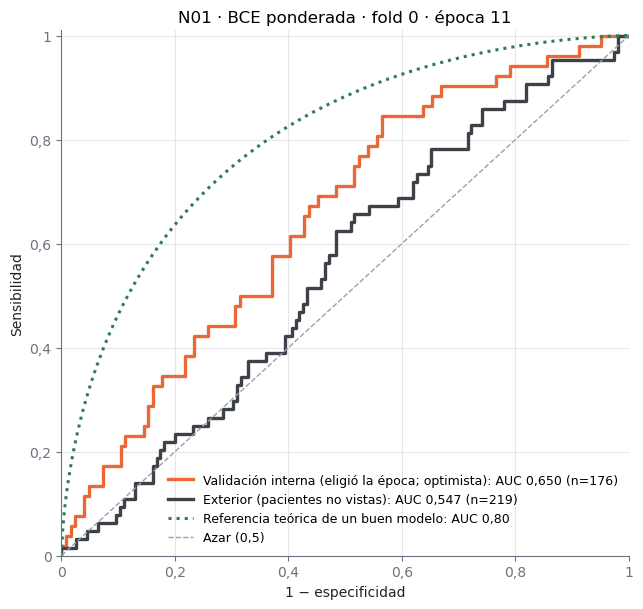

In [38]:
R.fig_roc_dos(R.N01, 'weighted', 0, 'N01')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

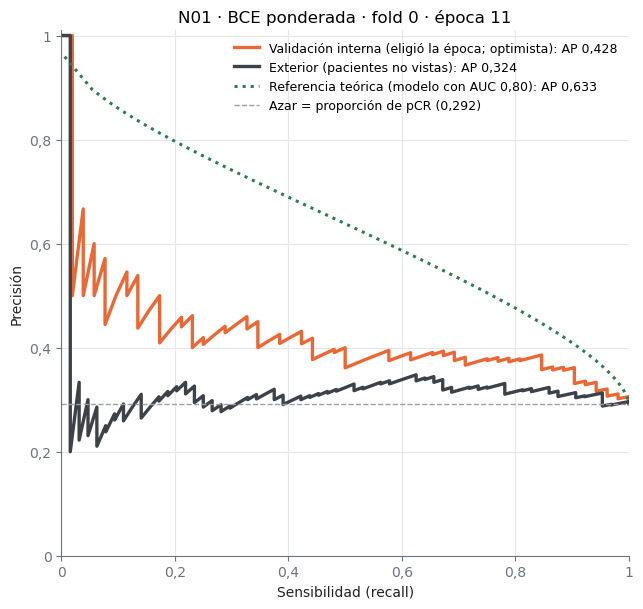

In [39]:
R.fig_pr_dos(R.N01, 'weighted', 0, 'N01')

In [40]:
R.tabla_umbrales(R.N01, 'weighted', 0)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,503",104,51,40,24,"0,375","0,671","0,320","0,523"
"0,325 (el de E57): 0,325",1,154,0,64,"1,000","0,006","0,294","0,503"
"0,5: 0,500",86,69,31,33,"0,516","0,555","0,324","0,535"


<a id="p01"></a>
## 4. P01: lotes con más pacientes

**Qué cambia.** Solo la composición del lote: 10 pacientes × 2 cortes al azar (distintos en cada recorrido) en lugar de 2 pacientes × 10 cortes. Se mantienen las mismas 20 imágenes por paso y los mismos pasos por época, la misma red E57 (298.161 parámetros), las mismas particiones, el mismo optimizador (AdamW, LR 0,001, WD 0,001, ReduceLROnPlateau) y la misma regla de selección. Criterios y lectura completa en [P01_LOTES.md](P01_LOTES.md).

### Paso 1 · ¿Puede memorizar? (40 pacientes, 30 épocas)

Antes de entrenar con todo, se comprueba si cada receta es capaz de memorizar un grupo pequeño. Una red que no memoriza 40 pacientes no puede aprender nada útil de 702.

In [41]:
R.tabla_memorizacion()

Receta,AUC en la época 4,"Primera época con AUC ≥ 0,90",AUC en la época 30,"Pérdida media, 5 últimas épocas"
E57 · 2 pacientes × 10 cortes,"0,695",23,"0,943","0,578"
P01 · 10 pacientes × 2 cortes,"1,000",3,"1,000","0,082"


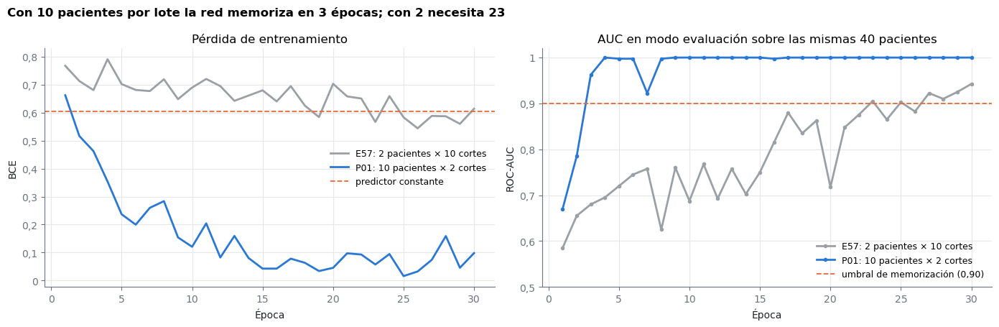

In [42]:
R.fig_memorizacion()

**Lectura.** P01 memoriza en 3–4 épocas y su pérdida cae hasta 0,03–0,16. E57 también llega a 0,94, pero tarda 23 épocas y su pérdida de entrenamiento no baja de 0,54. El criterio fijado era que E57 no pasara de 0,75: lo superó, así que la hipótesis de que E57 *no podía* aprender era demasiado fuerte. Aun así, la composición del lote cambia la velocidad de aprendizaje en un orden de magnitud.

### Paso 2 · Fold 0 con las 702 pacientes

### P01 · BCE normal · fold 0 · 16 épocas · checkpoint de época 6

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [43]:
R.tabla_epocas(R.P01, 'normal', 0)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.624250,0.627419,0.634796,0.467213,0.414702,0.467851,0.417495,"0,001",84
2,0.613061,0.602520,0.594662,0.566924,0.597395,0.564007,0.590103,"0,001",82
3,0.611766,0.598639,0.598511,0.579441,0.591656,0.575765,0.584987,"0,001",82
4,0.608222,0.596227,0.611557,0.615223,0.502171,0.608518,0.507841,"0,001",81
5,0.608768,0.588545,0.608179,0.648528,0.541408,0.642936,0.538938,"0,001",81
6,0.602779,0.594832,0.601275,0.592742,0.610887,0.591794,0.607903,"0,001",85
7,0.595602,0.579883,0.617034,0.648401,0.538617,0.646411,0.538055,"0,001",83
8,0.589743,0.571062,0.618382,0.715051,0.508995,0.707135,0.507601,"0,001",84
9,0.584625,0.610394,0.687122,0.709511,0.557537,0.704872,0.557516,"0,001",84
10,0.576146,0.545523,0.627789,0.722352,0.518766,0.715583,0.519769,"0,001",84


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

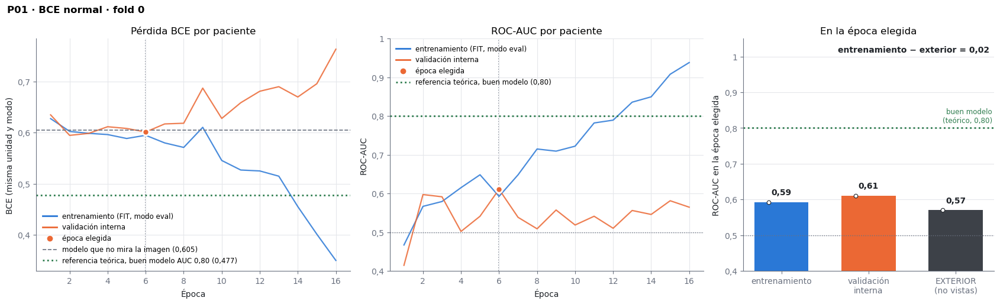

In [44]:
R.fig_tres(R.P01, 'normal', 0, 'P01')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

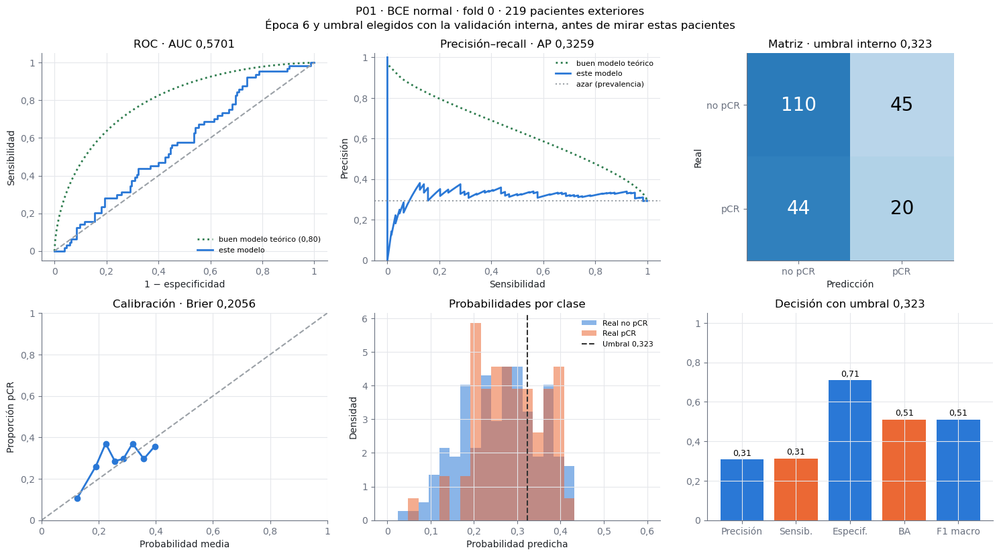

In [45]:
R.fig_resultados(R.P01, 'normal', 0, 'P01')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

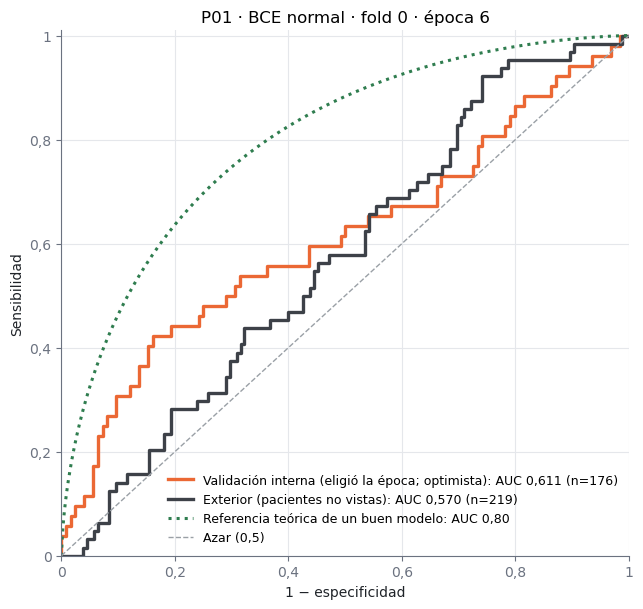

In [46]:
R.fig_roc_dos(R.P01, 'normal', 0, 'P01')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

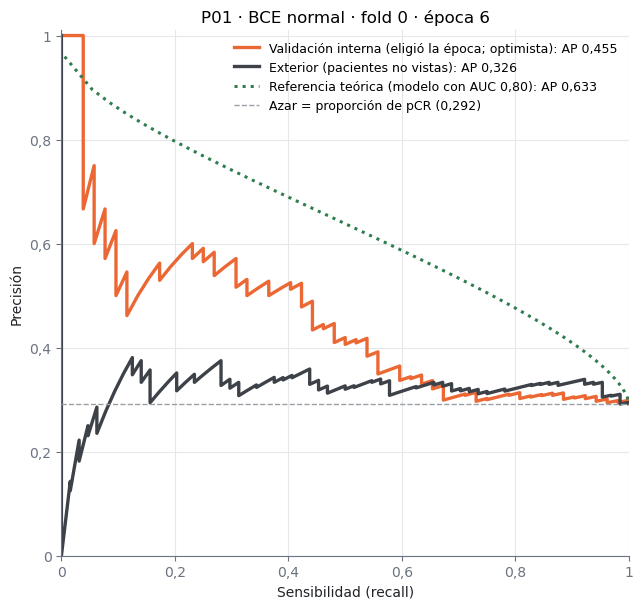

In [47]:
R.fig_pr_dos(R.P01, 'normal', 0, 'P01')

In [48]:
R.tabla_umbrales(R.P01, 'normal', 0)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,323",110,45,44,20,"0,312","0,710","0,308","0,511"
"0,325 (el de E57): 0,325",113,42,44,20,"0,312","0,729","0,323","0,521"
"0,5: 0,500",155,0,64,0,"0,000","1,000",—,"0,500"


**Conclusión de P01.** La red por fin aprende: el AUC en train pasa de 0,47 a 0,94. Pero lo que aprende no se traslada: la validación interna se queda plana entre 0,50 y 0,61 y su pérdida sube desde la época 3. Es memorización. AUC exterior 0,570 (N01 normal, 0,617). La siguiente palanca, fijada de antemano, era regularizar con aumento de datos.

<a id="p02"></a>
## 5. P02: aumento geométrico sincronizado

**Qué cambia.** P01 más aumento geométrico **solo en entrenamiento**: volteo horizontal y vertical (probabilidad 0,5 cada uno), giro de hasta ±10° y traslación de hasta ±3 %. La misma transformación se aplica a PRE, EARLY y LATE, para no desalinear las fases y no destruir el realce. Evaluación y web no cambian. Es la primera vez que el aumento se prueba sobre una receta que aprende; las pruebas anteriores (E37, E49, D16, D18) eran sobre recetas que no aprendían. Criterios en [P02_AUMENTO.md](P02_AUMENTO.md).

La imagen muestra un corte real con cuatro aumentos: el mapa de realce sigue nítido, prueba de que las fases se transforman juntas.

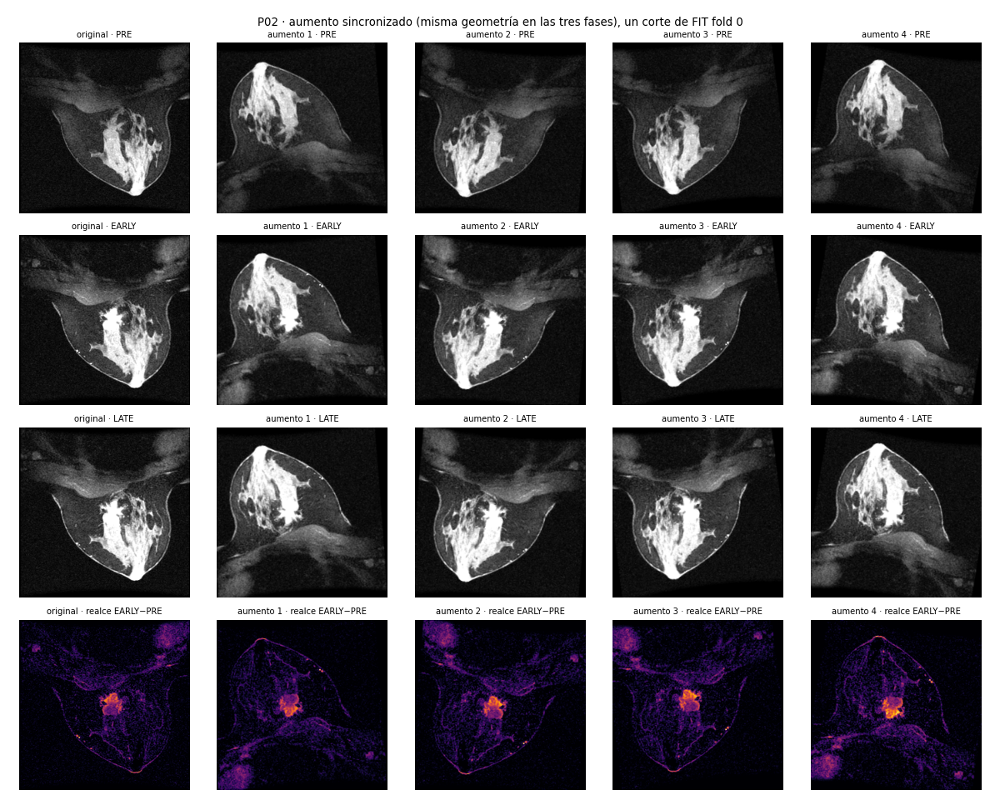

In [49]:
display(Image(filename=str(R.NA/'P02_aumento_geometrico/vista_aumento.png'), width=950))

### P02 (Mac) · BCE normal · fold 0 · 24 épocas · checkpoint de época 14

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [50]:
R.tabla_epocas(R.P02, 'normal', 0)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.625609,0.633344,0.628954,0.512762,0.476272,0.511735,0.473010,"0,001",90
2,0.613554,0.605925,0.610114,0.539129,0.501551,0.538607,0.497301,"0,001",90
3,0.609969,0.610309,0.604634,0.551137,0.583282,0.550588,0.576934,"0,001",89
4,0.607732,0.605952,0.610272,0.581771,0.586694,0.578887,0.587717,"0,001",90
5,0.608301,0.598430,0.596265,0.571484,0.607010,0.569161,0.604101,"0,001",90
6,0.604370,0.593729,0.593537,0.592213,0.624380,0.590996,0.623145,"0,001",91
7,0.599902,0.601741,0.603021,0.595394,0.593828,0.592645,0.592344,"0,001",91
8,0.604233,0.609588,0.601121,0.546293,0.581110,0.543849,0.578291,"0,001",89
9,0.601370,0.645630,0.661402,0.605426,0.603133,0.601071,0.597061,"0,001",89
10,0.598520,0.597041,0.603288,0.609869,0.595999,0.604336,0.591401,"0,001",90


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

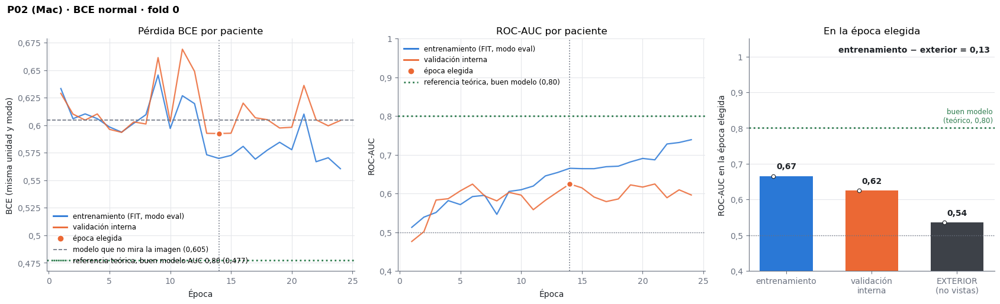

In [51]:
R.fig_tres(R.P02, 'normal', 0, 'P02 (Mac)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

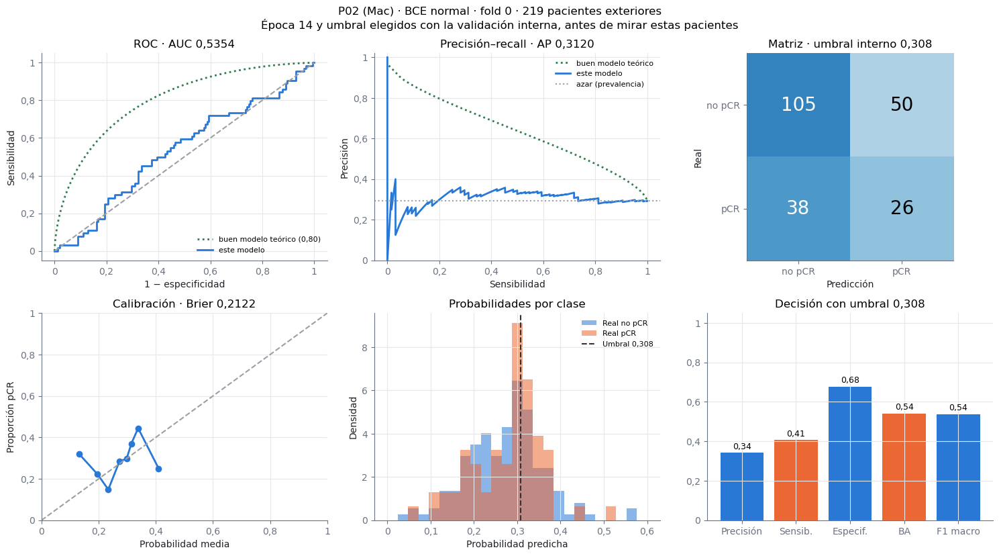

In [52]:
R.fig_resultados(R.P02, 'normal', 0, 'P02 (Mac)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

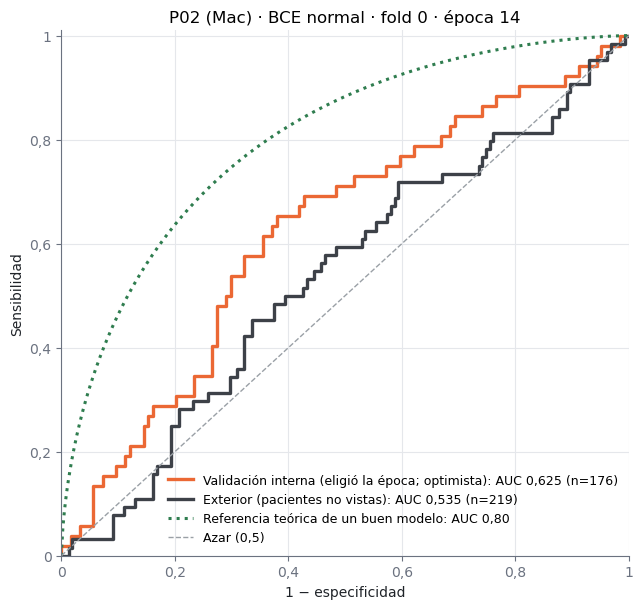

In [53]:
R.fig_roc_dos(R.P02, 'normal', 0, 'P02 (Mac)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

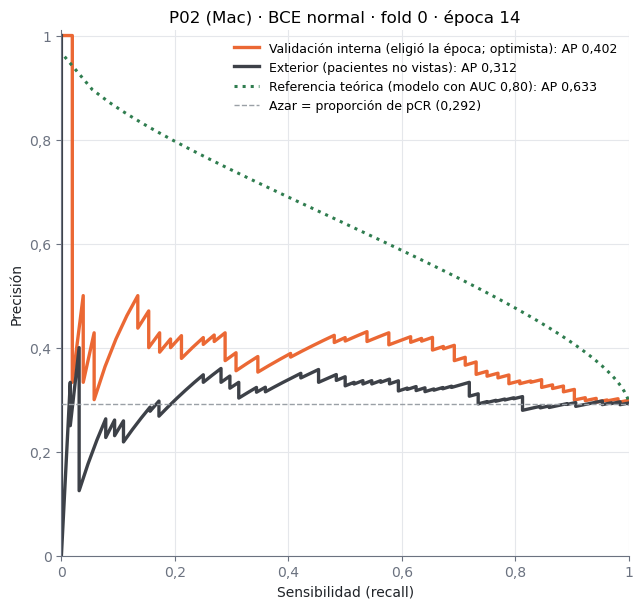

In [54]:
R.fig_pr_dos(R.P02, 'normal', 0, 'P02 (Mac)')

In [55]:
R.tabla_umbrales(R.P02, 'normal', 0)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,308",105,50,38,26,"0,406","0,677","0,342","0,542"
"0,325 (el de E57): 0,325",116,39,45,19,"0,297","0,748","0,328","0,523"
"0,5: 0,500",153,2,63,1,"0,016","0,987","0,333","0,501"


**Conclusión de P02 en el fold 0.** El aumento frena la memorización: la diferencia final entre train e interna baja de 0,37 a 0,14 y la pérdida interna se mantiene estable. Pero la interna no pasa de 0,625 y el exterior es 0,535. Entre N01, P01 y P02 la interna sube (0,572, 0,611, 0,625) y el exterior baja (0,617, 0,570, 0,535): con un fold no se pueden ordenar recetas. Por la regla fijada antes, se pasa a la validación cruzada completa con P02.

<a id="cv"></a>
## 6. P02 en 5 folds: BCE normal frente a ponderada

**Qué se mide.** Los 5 folds con BCE normal y con BCE ponderada (`pos_weight = N0/N1` de las pacientes FIT, ≈ 2,4), entrenados en la GPU de la universidad con la misma receta y particiones. Así cada una de las 1.097 pacientes de train tiene una predicción de un modelo que no la vio, y el error típico del AUC baja a ≈ 0,018. Es además la comparación de pérdidas que exige el enunciado.

### Resumen de los 5 folds

Una fila por entrenamiento. Sensibilidad, especificidad, BA y matriz usan el umbral interno de cada fold.

In [56]:
R.cv_tabla_folds()

Pérdida,Fold,Épocas,Época elegida,AUC train,AUC interna,AUC exterior,AP exterior,Sensibilidad,Especificidad,BA,TN,FP,FN,TP
normal,0,19,9,"0,646","0,650","0,561","0,345","0,484","0,606","0,545",94,61,33,31
normal,1,29,19,"0,681","0,643","0,543","0,335","0,452","0,669","0,560",105,52,34,28
normal,2,11,1,"0,566","0,555","0,546","0,299","0,322","0,708","0,515",114,47,40,19
normal,3,11,1,"0,613","0,574","0,479","0,362","0,240","0,759","0,499",110,35,57,18
normal,4,12,2,"0,605","0,542","0,553","0,326","0,387","0,669","0,528",105,52,38,24
ponderada,0,20,10,"0,581","0,617","0,511","0,290","0,203","0,774","0,489",120,35,51,13
ponderada,1,22,12,"0,606","0,606","0,518","0,317","0,355","0,701","0,528",110,47,40,22
ponderada,2,22,12,"0,606","0,597","0,476","0,267","0,136","0,820","0,478",132,29,51,8
ponderada,3,11,1,"0,596","0,566","0,478","0,378","0,333","0,621","0,477",90,55,50,25
ponderada,4,13,3,"0,591","0,563","0,540","0,315","0,387","0,656","0,522",103,54,38,24


### AUC conjunta y comparación pareada

La *AUC conjunta* junta las predicciones exteriores de los 5 modelos; la *media de folds* evalúa cada modelo por separado. Se reportan las dos. La comparación pareada usa exactamente las mismas pacientes con cada pérdida.

In [57]:
tabla, texto = R.cv_resumen()
display(tabla)
display(Markdown(texto))

Pérdida,Folds,Pacientes,AUC exterior conjunta,IC95 inferior,IC95 superior,Media de folds,AUC por corte,AP,Brier
normal,5,1097,"0,532","0,493","0,570","0,536","0,529","0,326","0,212"
ponderada,5,1097,"0,500","0,464","0,535","0,505","0,501","0,296","0,243"


**Normal − ponderada** sobre las mismas 1097 pacientes: 0,032 (IC95 -0,001 a 0,064). El intervalo incluye 0: **no hay diferencia demostrada** entre las dos pérdidas.

### Gráficas conjuntas

Curvas de los 5 folds para cada pérdida, matrices sumando los folds (umbral interno, 0,325 y 0,5), ROC y PR, AUC por cohorte y por corte, y calibración.

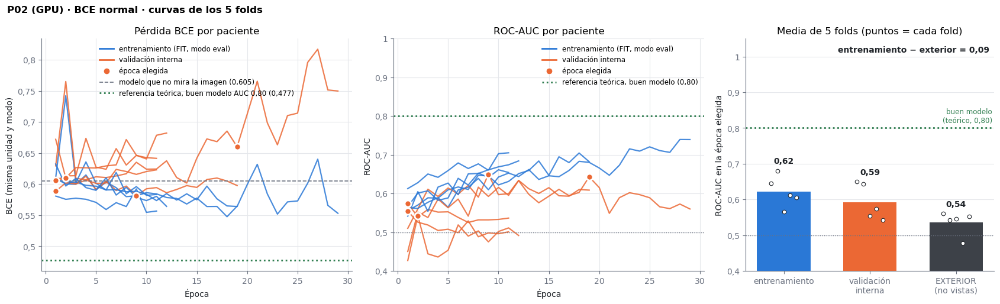

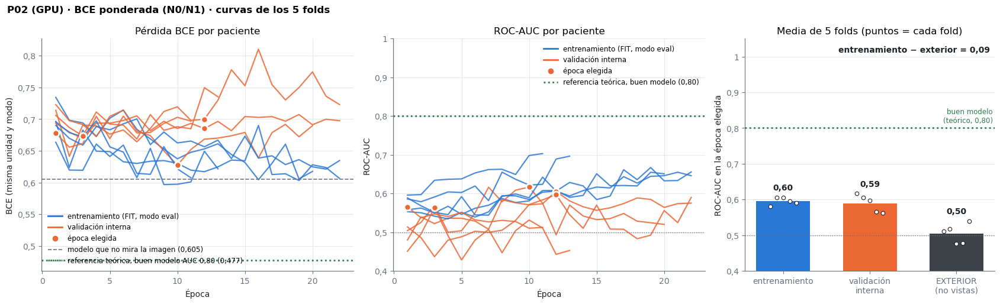

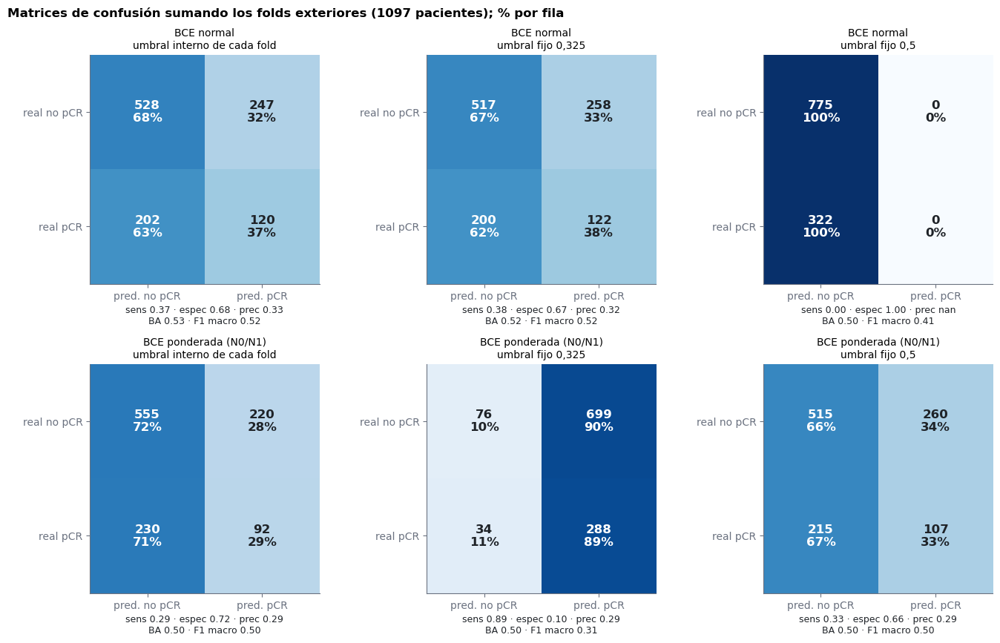

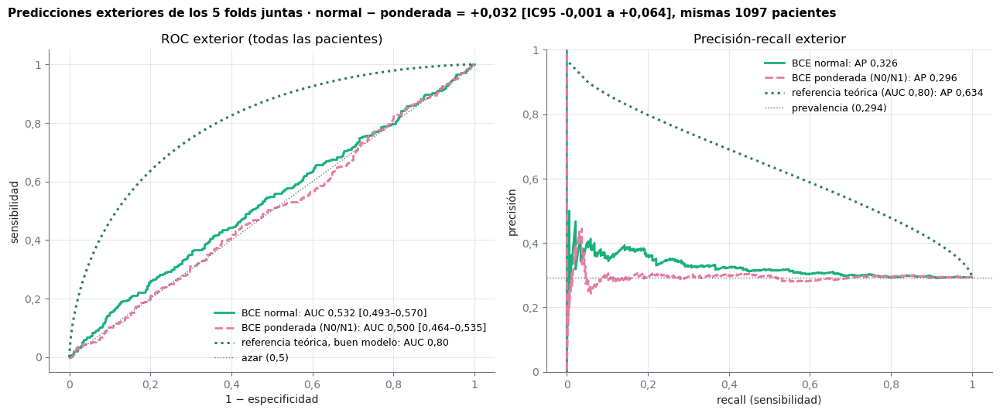

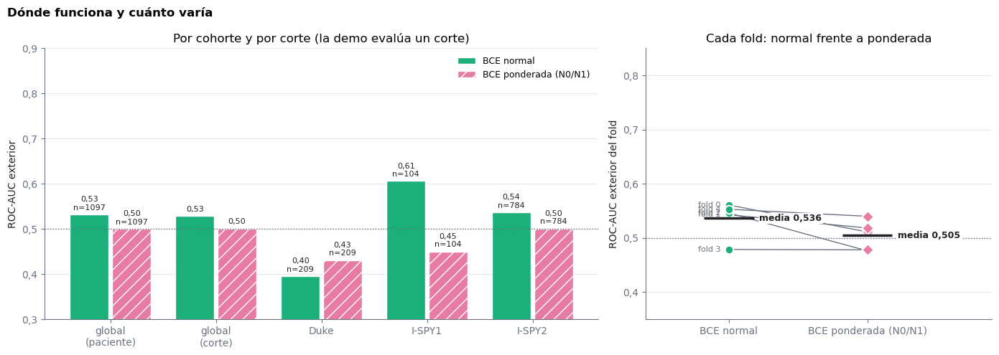

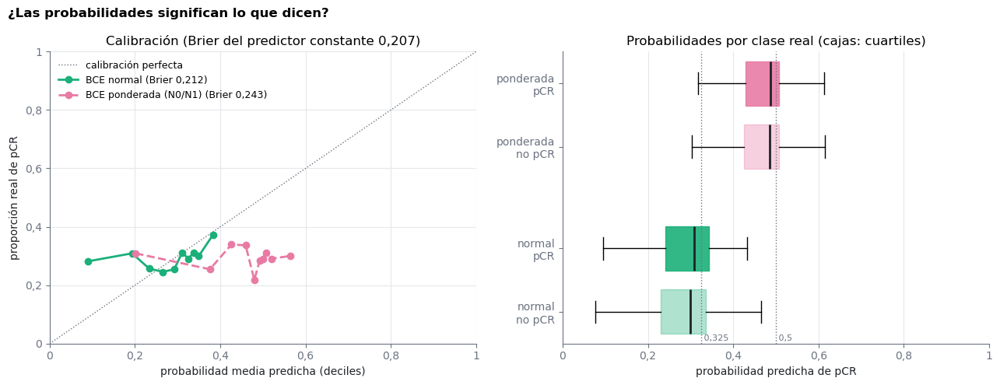

In [58]:
for fig in R.cv_figuras():
    display(fig)

### Detalle por entrenamiento

#### P02 (GPU) · BCE normal · fold 0 · 19 épocas · checkpoint de época 9

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [59]:
R.tabla_epocas(R.P02_GPU, 'normal', 0)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.623435,0.609112,0.611548,0.556227,0.510081,0.552750,0.514709,"0,001",74
2,0.606948,0.600299,0.604637,0.570300,0.560484,0.567561,0.555965,"0,001",73
3,0.612151,0.599751,0.601078,0.589013,0.611197,0.586789,0.608147,"0,001",72
4,0.606749,0.614800,0.612659,0.588259,0.592587,0.585386,0.589382,"0,001",73
5,0.605375,0.591026,0.591414,0.609605,0.614299,0.605177,0.607964,"0,001",73
6,0.601113,0.603284,0.604784,0.617014,0.598635,0.611924,0.595526,"0,001",73
7,0.599047,0.594307,0.589694,0.610574,0.621123,0.609351,0.616085,"0,001",73
8,0.598522,0.579924,0.596930,0.647177,0.590881,0.641124,0.591290,"0,001",73
9,0.593625,0.581253,0.581485,0.645523,0.649659,0.641209,0.640084,"0,001",73
10,0.593912,0.586224,0.592478,0.622328,0.597084,0.620482,0.592942,"0,001",73


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

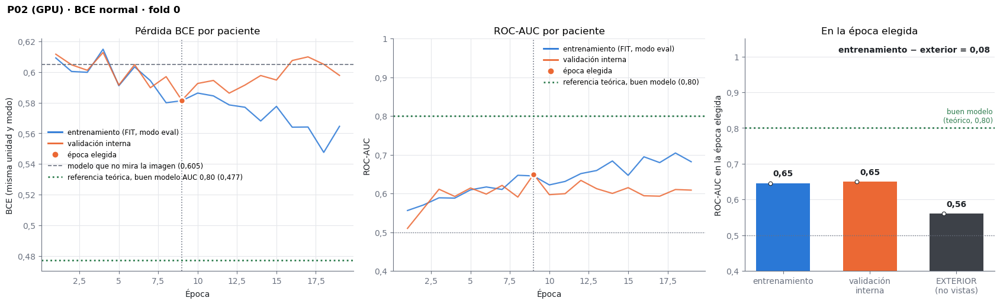

In [60]:
R.fig_tres(R.P02_GPU, 'normal', 0, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

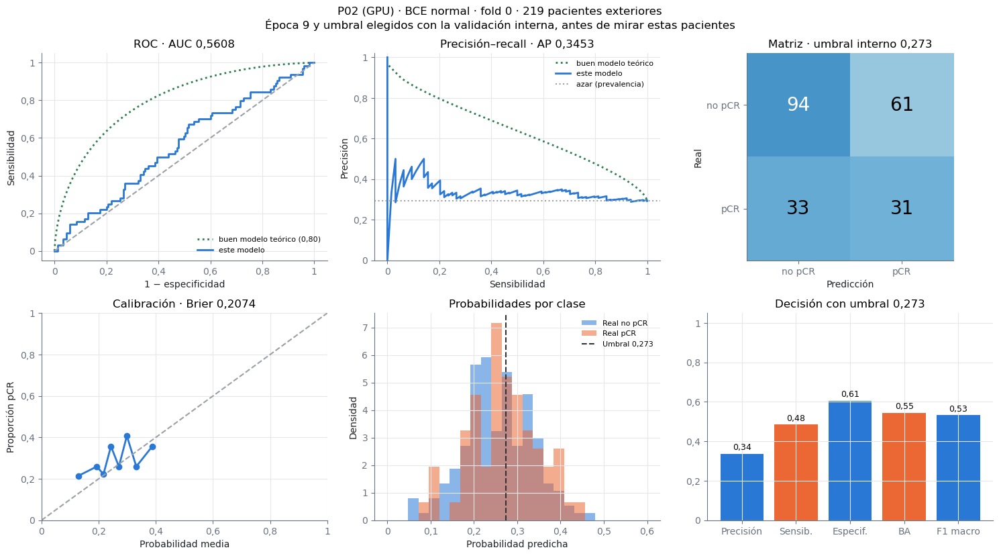

In [61]:
R.fig_resultados(R.P02_GPU, 'normal', 0, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

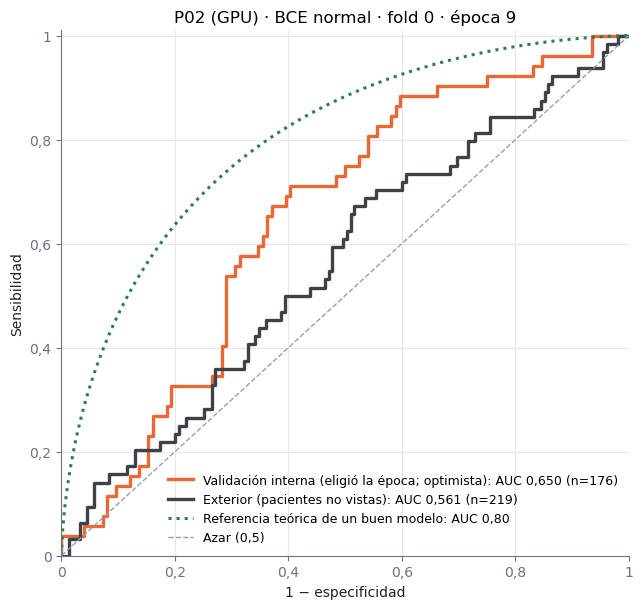

In [62]:
R.fig_roc_dos(R.P02_GPU, 'normal', 0, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

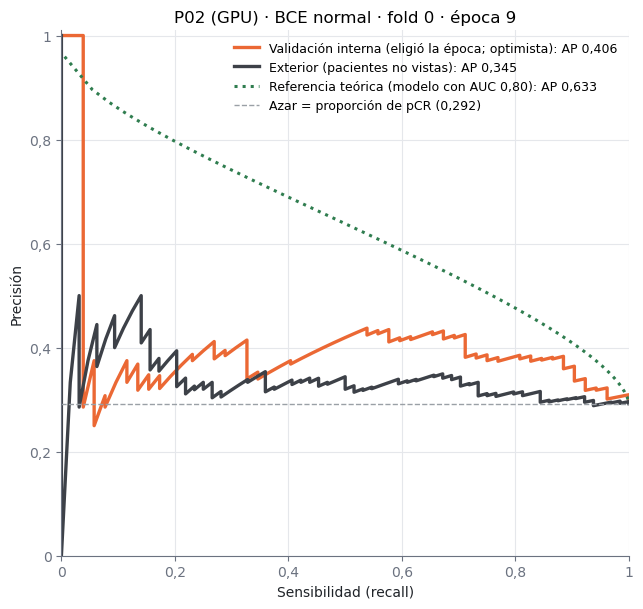

In [63]:
R.fig_pr_dos(R.P02_GPU, 'normal', 0, 'P02 (GPU)')

In [64]:
R.tabla_umbrales(R.P02_GPU, 'normal', 0)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,273",94,61,33,31,"0,484","0,606","0,337","0,545"
"0,325 (el de E57): 0,325",124,31,50,14,"0,219","0,800","0,311","0,509"
"0,5: 0,500",155,0,64,0,"0,000","1,000",—,"0,500"


#### P02 (GPU) · BCE normal · fold 1 · 29 épocas · checkpoint de época 19

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [65]:
R.tabla_epocas(R.P02_GPU, 'normal', 1)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.620809,0.610401,0.629407,0.563045,0.450372,0.561432,0.452213,"0,001",74
2,0.609086,0.742289,0.765191,0.561673,0.552109,0.561548,0.553100,"0,001",73
3,0.609016,0.603414,0.609361,0.577458,0.538151,0.574547,0.535199,"0,001",73
4,0.610533,0.597940,0.606993,0.589273,0.585453,0.587134,0.581051,"0,001",73
5,0.607069,0.596734,0.611852,0.564661,0.563431,0.564385,0.559813,"0,001",73
6,0.602027,0.590663,0.610640,0.609283,0.585763,0.607975,0.577053,"0,001",73
7,0.600632,0.591054,0.613189,0.616222,0.541718,0.612110,0.540180,"0,001",72
8,0.598510,0.587798,0.616732,0.639082,0.616470,0.634265,0.612368,"0,001",73
9,0.598243,0.588478,0.635226,0.609818,0.592587,0.608558,0.590645,"0,001",72
10,0.595497,0.583766,0.624105,0.642635,0.615850,0.637633,0.613395,"0,001",73


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

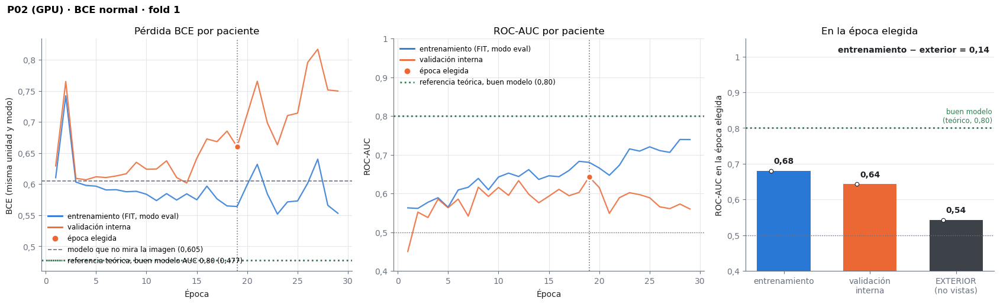

In [66]:
R.fig_tres(R.P02_GPU, 'normal', 1, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

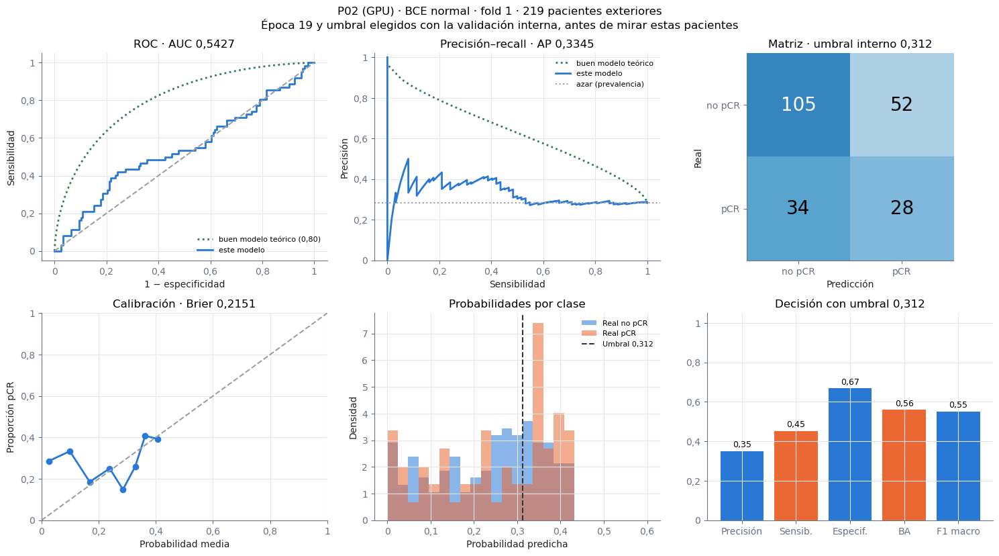

In [67]:
R.fig_resultados(R.P02_GPU, 'normal', 1, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

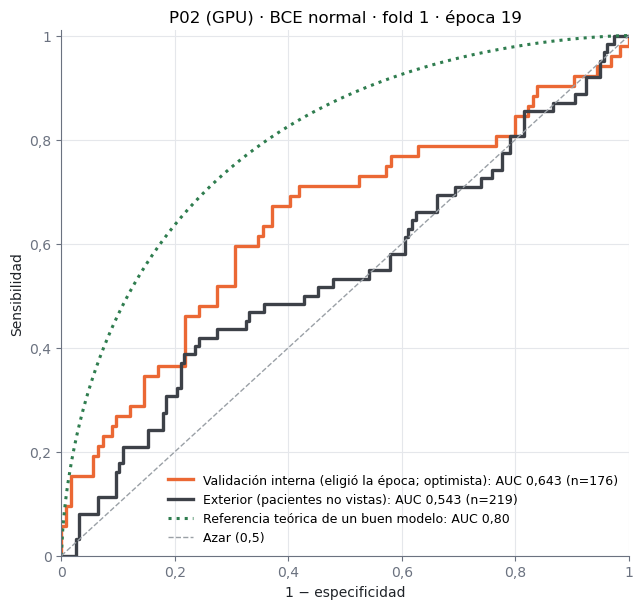

In [68]:
R.fig_roc_dos(R.P02_GPU, 'normal', 1, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

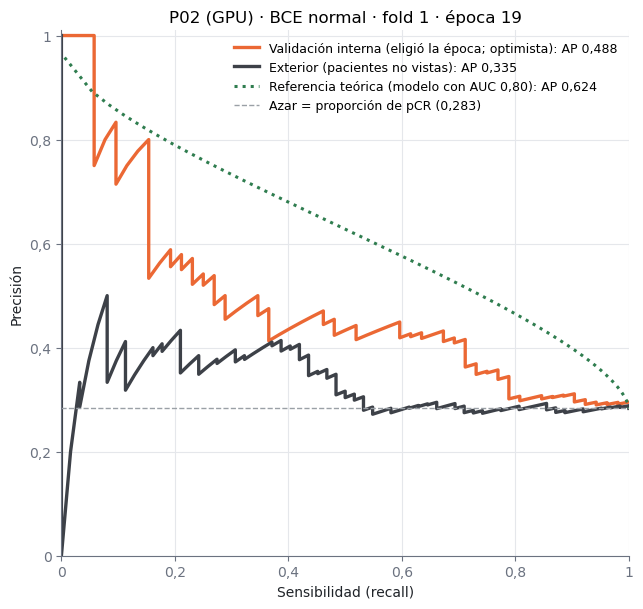

In [69]:
R.fig_pr_dos(R.P02_GPU, 'normal', 1, 'P02 (GPU)')

In [70]:
R.tabla_umbrales(R.P02_GPU, 'normal', 1)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,312",105,52,34,28,"0,452","0,669","0,350","0,560"
"0,325 (el de E57): 0,325",114,43,35,27,"0,435","0,726","0,386","0,581"
"0,5: 0,500",157,0,62,0,"0,000","1,000",—,"0,500"


#### P02 (GPU) · BCE normal · fold 2 · 11 épocas · checkpoint de época 1

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [71]:
R.tabla_epocas(R.P02_GPU, 'normal', 2)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.623288,0.607601,0.606108,0.566104,0.554533,0.563221,0.555527,"0,001",78
2,0.614757,0.603931,0.613339,0.601435,0.526001,0.597649,0.524893,"0,001",73
3,0.613633,0.602228,0.613610,0.606934,0.518791,0.603433,0.520707,"0,001",73
4,0.610069,0.635737,0.673746,0.582524,0.504679,0.579711,0.502997,"0,001",73
5,0.605777,0.601593,0.627338,0.588711,0.507900,0.584575,0.510143,"0,001",73
6,0.602411,0.590531,0.623976,0.639366,0.499003,0.631814,0.502086,"0,0005",73
7,0.598777,0.618706,0.657218,0.622015,0.529376,0.617535,0.527701,"0,0005",73
8,0.600757,0.584610,0.630727,0.652730,0.488418,0.644374,0.485943,"0,0005",73
9,0.599750,0.596076,0.646178,0.641616,0.498389,0.635205,0.499615,"0,0005",73
10,0.593849,0.582066,0.642642,0.661391,0.496242,0.653289,0.496346,"0,00025",73


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

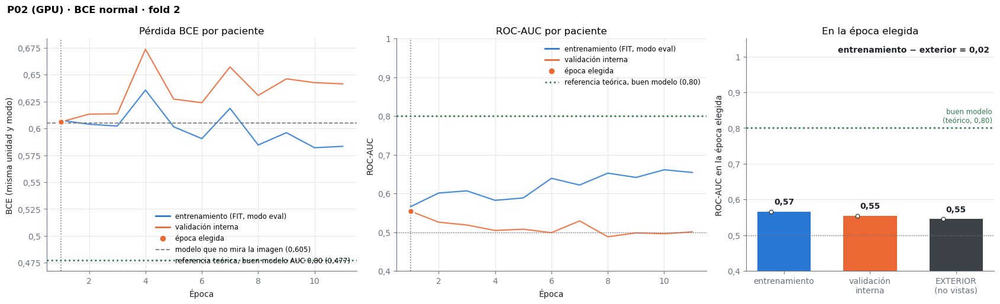

In [72]:
R.fig_tres(R.P02_GPU, 'normal', 2, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

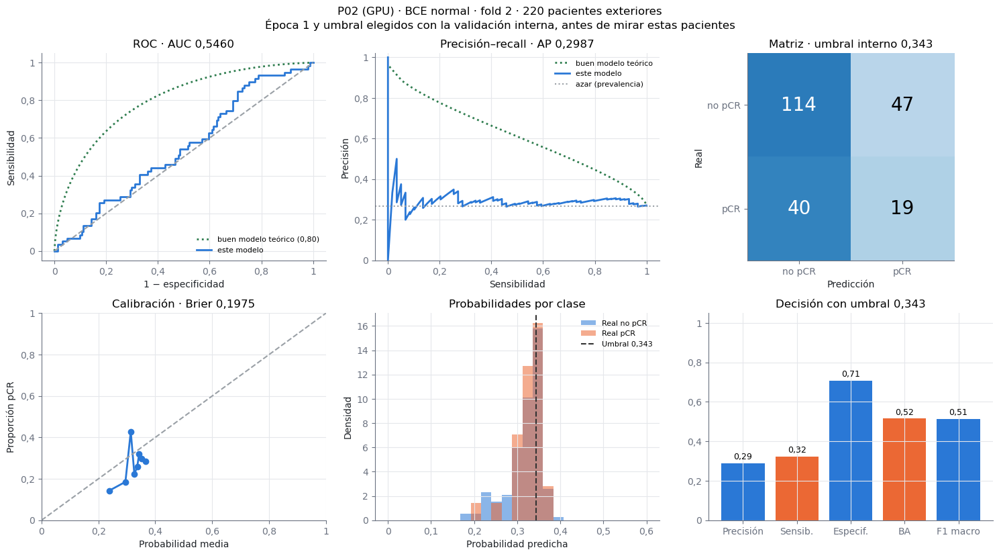

In [73]:
R.fig_resultados(R.P02_GPU, 'normal', 2, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

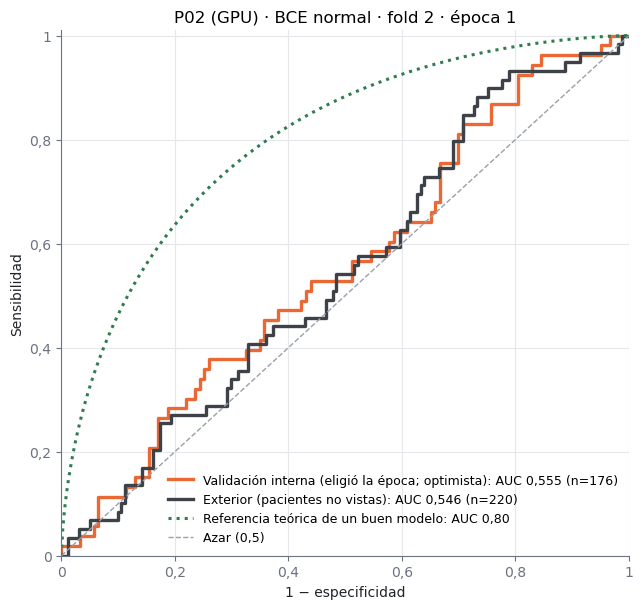

In [74]:
R.fig_roc_dos(R.P02_GPU, 'normal', 2, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

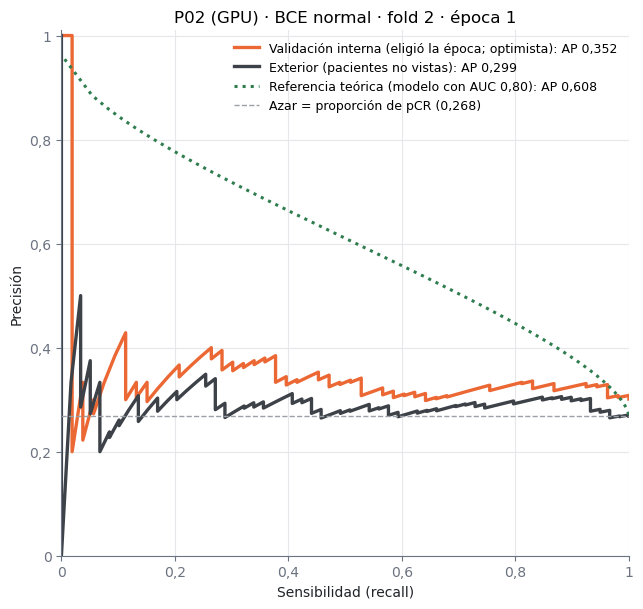

In [75]:
R.fig_pr_dos(R.P02_GPU, 'normal', 2, 'P02 (GPU)')

In [76]:
R.tabla_umbrales(R.P02_GPU, 'normal', 2)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,343",114,47,40,19,"0,322","0,708","0,288","0,515"
"0,325 (el de E57): 0,325",67,94,24,35,"0,593","0,416","0,271","0,505"
"0,5: 0,500",161,0,59,0,"0,000","1,000",—,"0,500"


#### P02 (GPU) · BCE normal · fold 3 · 11 épocas · checkpoint de época 1

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [77]:
R.tabla_epocas(R.P02_GPU, 'normal', 3)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.606575,0.580885,0.588645,0.612823,0.574127,0.607096,0.570638,"0,001",73
2,0.592252,0.575594,0.602090,0.628112,0.540000,0.623792,0.543353,"0,001",72
3,0.584001,0.577361,0.600294,0.650481,0.558889,0.644916,0.564404,"0,001",72
4,0.585987,0.575679,0.606472,0.641910,0.552063,0.636396,0.553314,"0,001",72
5,0.584643,0.570673,0.601257,0.659334,0.552857,0.652538,0.558754,"0,001",72
6,0.573707,0.559181,0.601813,0.679095,0.538413,0.670993,0.543708,"0,0005",72
7,0.572787,0.570183,0.623714,0.664683,0.525397,0.660232,0.530338,"0,0005",72
8,0.574630,0.563932,0.620342,0.676668,0.532063,0.670095,0.537641,"0,0005",72
9,0.565296,0.592330,0.615714,0.660180,0.532063,0.650102,0.533556,"0,0005",72
10,0.559020,0.554595,0.620309,0.703026,0.533175,0.692960,0.539543,"0,00025",73


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

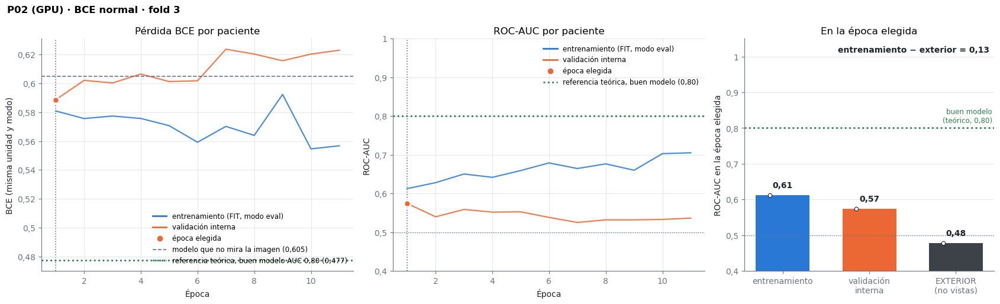

In [78]:
R.fig_tres(R.P02_GPU, 'normal', 3, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

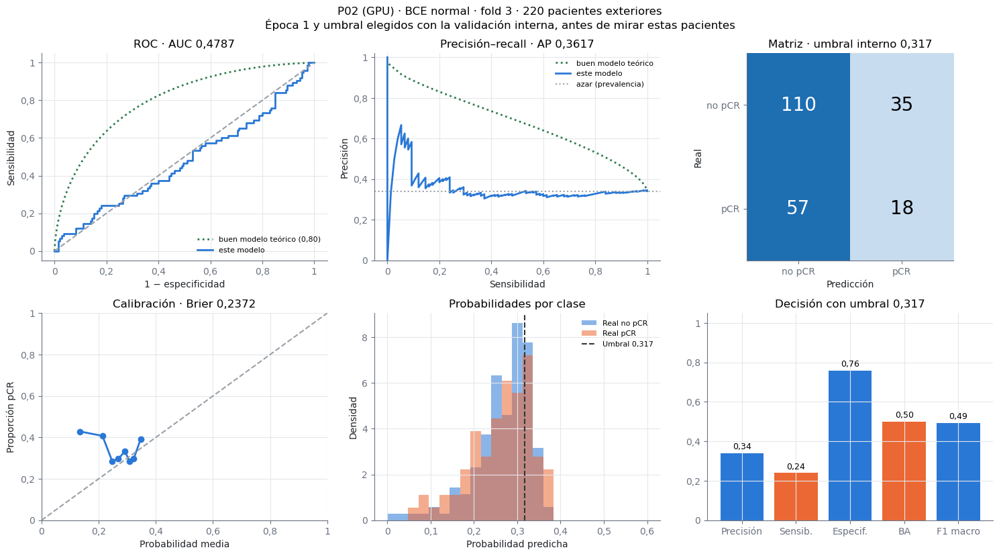

In [79]:
R.fig_resultados(R.P02_GPU, 'normal', 3, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

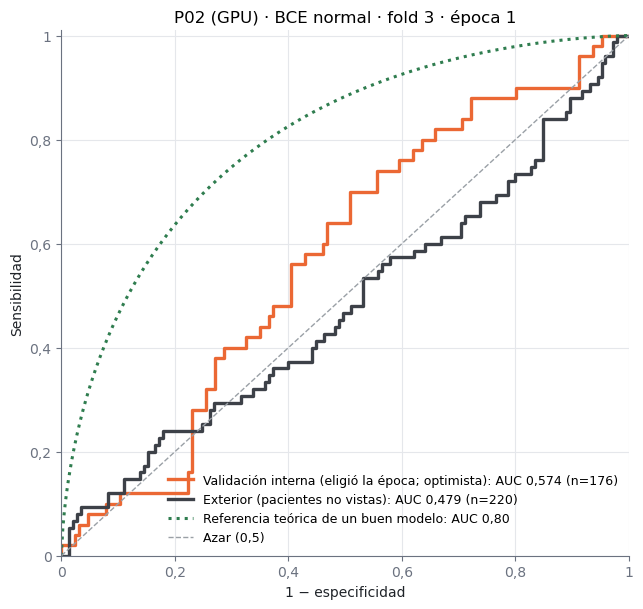

In [80]:
R.fig_roc_dos(R.P02_GPU, 'normal', 3, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

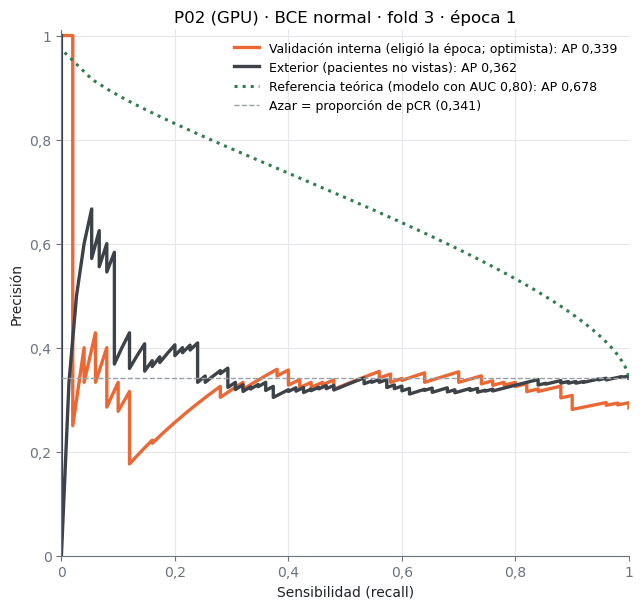

In [81]:
R.fig_pr_dos(R.P02_GPU, 'normal', 3, 'P02 (GPU)')

In [82]:
R.tabla_umbrales(R.P02_GPU, 'normal', 3)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,317",110,35,57,18,"0,240","0,759","0,340","0,499"
"0,325 (el de E57): 0,325",123,22,61,14,"0,187","0,848","0,389","0,517"
"0,5: 0,500",145,0,75,0,"0,000","1,000",—,"0,500"


#### P02 (GPU) · BCE normal · fold 4 · 12 épocas · checkpoint de época 2

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [83]:
R.tabla_epocas(R.P02_GPU, 'normal', 4)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.621450,0.632446,0.672205,0.541527,0.427109,0.541335,0.428687,"0,001",73
2,0.612547,0.597006,0.609857,0.604923,0.542339,0.599329,0.538331,"0,001",73
3,0.609345,0.609199,0.626695,0.554111,0.444324,0.552612,0.442242,"0,001",73
4,0.606050,0.594422,0.626320,0.616708,0.436104,0.614724,0.435135,"0,001",73
5,0.604051,0.590067,0.626031,0.627034,0.453629,0.622425,0.455858,"0,001",73
6,0.602004,0.610211,0.629369,0.597137,0.519076,0.593715,0.515097,"0,001",73
7,0.595345,0.582490,0.631025,0.650781,0.490074,0.647778,0.491343,"0,0005",73
8,0.591495,0.594878,0.671789,0.651968,0.503567,0.648904,0.502787,"0,0005",73
9,0.588205,0.578872,0.646580,0.661174,0.475341,0.658017,0.474796,"0,0005",73
10,0.593900,0.573519,0.640518,0.668980,0.502016,0.665498,0.499692,"0,0005",72


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

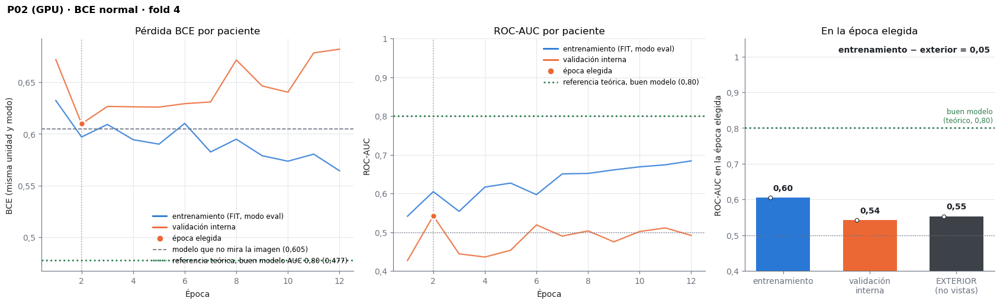

In [84]:
R.fig_tres(R.P02_GPU, 'normal', 4, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

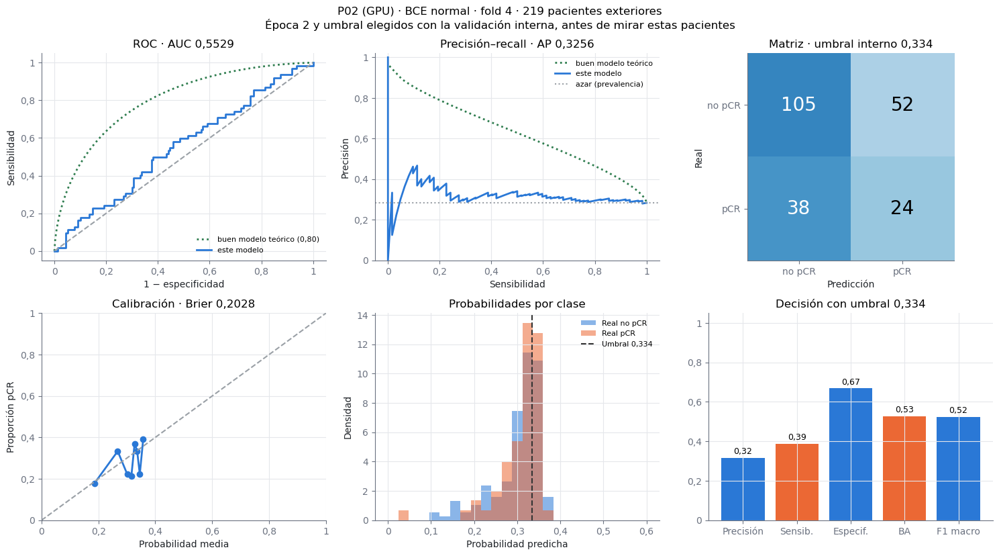

In [85]:
R.fig_resultados(R.P02_GPU, 'normal', 4, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

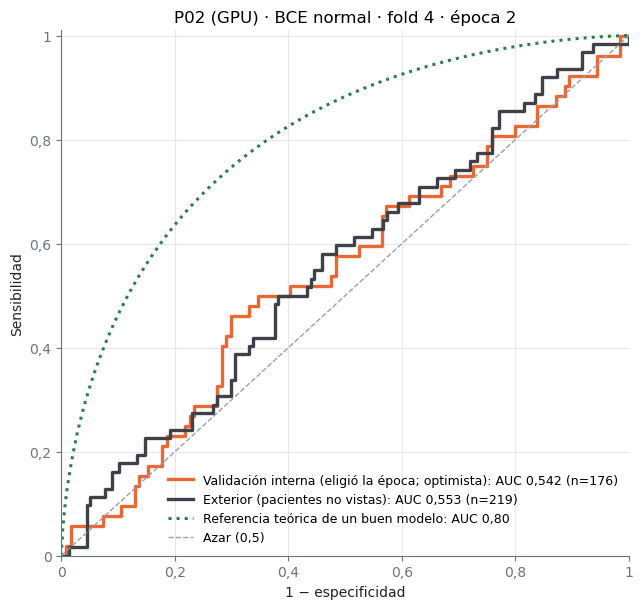

In [86]:
R.fig_roc_dos(R.P02_GPU, 'normal', 4, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

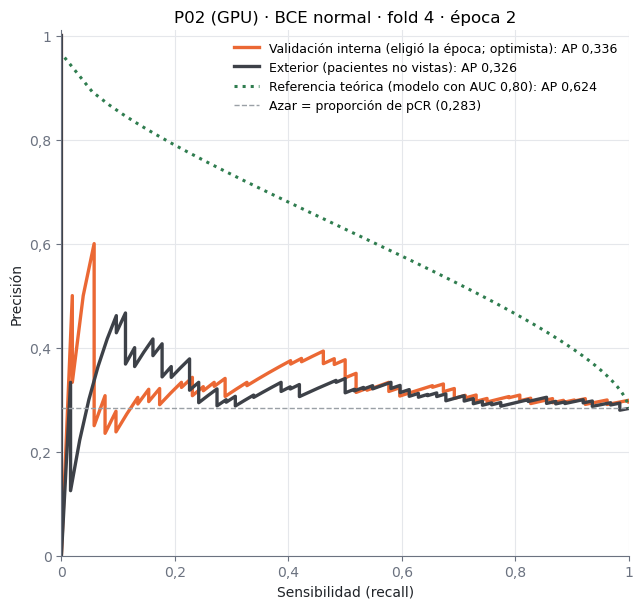

In [87]:
R.fig_pr_dos(R.P02_GPU, 'normal', 4, 'P02 (GPU)')

In [88]:
R.tabla_umbrales(R.P02_GPU, 'normal', 4)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,334",105,52,38,24,"0,387","0,669","0,316","0,528"
"0,325 (el de E57): 0,325",89,68,30,32,"0,516","0,567","0,320","0,542"
"0,5: 0,500",157,0,62,0,"0,000","1,000",—,"0,500"


#### P02 (GPU) · BCE ponderada · fold 0 · 20 épocas · checkpoint de época 10

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [89]:
R.tabla_epocas(R.P02_GPU, 'weighted', 0)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.998769,0.734337,0.722834,0.558272,0.504342,0.555794,0.505660,"0,001",74
2,0.976895,0.698295,0.697580,0.562461,0.525434,0.560568,0.520174,"0,001",72
3,0.978679,0.694037,0.691478,0.549757,0.570099,0.548708,0.558226,"0,001",72
4,0.973894,0.673000,0.672379,0.567119,0.500000,0.567992,0.497550,"0,001",73
5,0.975180,0.701505,0.704459,0.546146,0.504032,0.546934,0.495171,"0,001",72
6,0.968294,0.714362,0.714009,0.561991,0.549783,0.561838,0.548971,"0,001",72
7,0.971861,0.683836,0.680958,0.569904,0.616393,0.567833,0.609903,"0,001",72
8,0.968267,0.668931,0.673970,0.587095,0.578551,0.586683,0.574872,"0,001",72
9,0.962788,0.652664,0.649969,0.576818,0.608716,0.575242,0.609775,"0,001",72
10,0.962535,0.637435,0.627397,0.581154,0.616703,0.580383,0.616615,"0,001",73


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

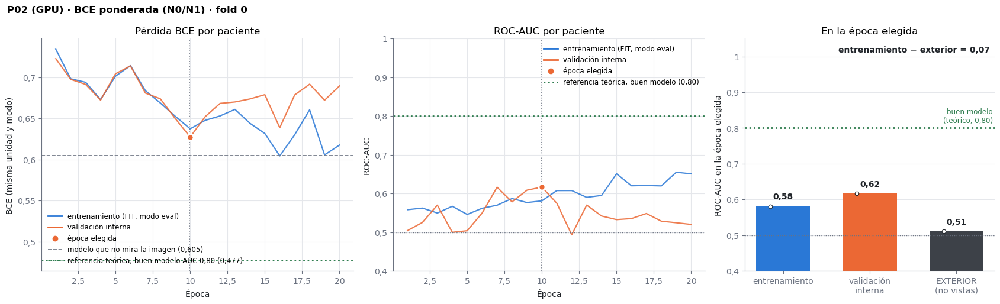

In [90]:
R.fig_tres(R.P02_GPU, 'weighted', 0, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

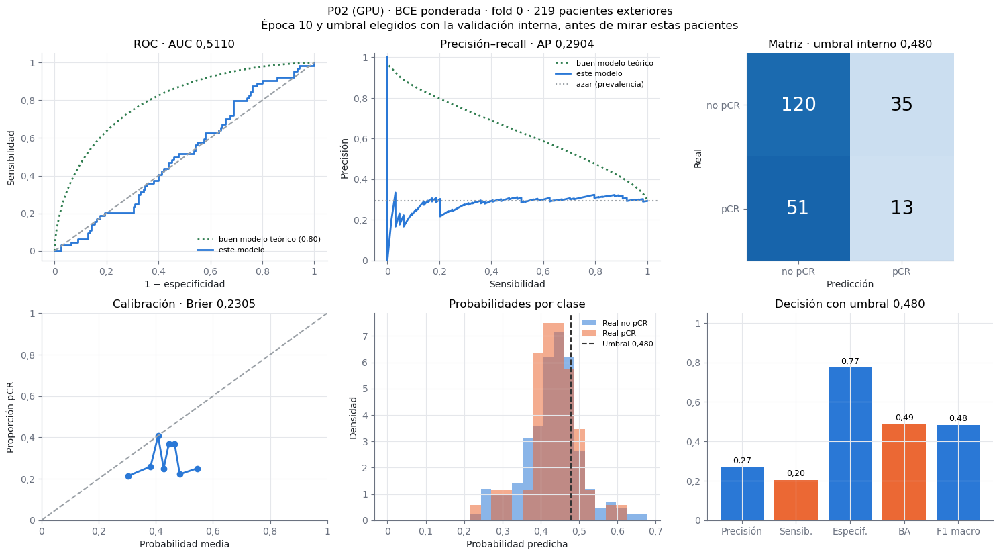

In [91]:
R.fig_resultados(R.P02_GPU, 'weighted', 0, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

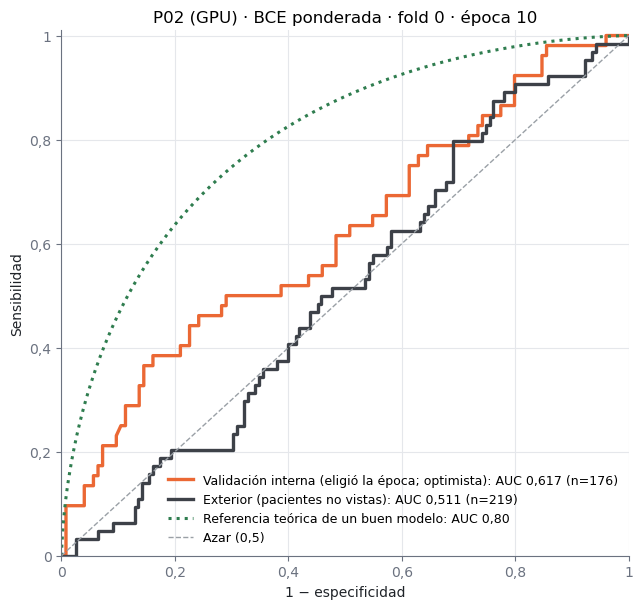

In [92]:
R.fig_roc_dos(R.P02_GPU, 'weighted', 0, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

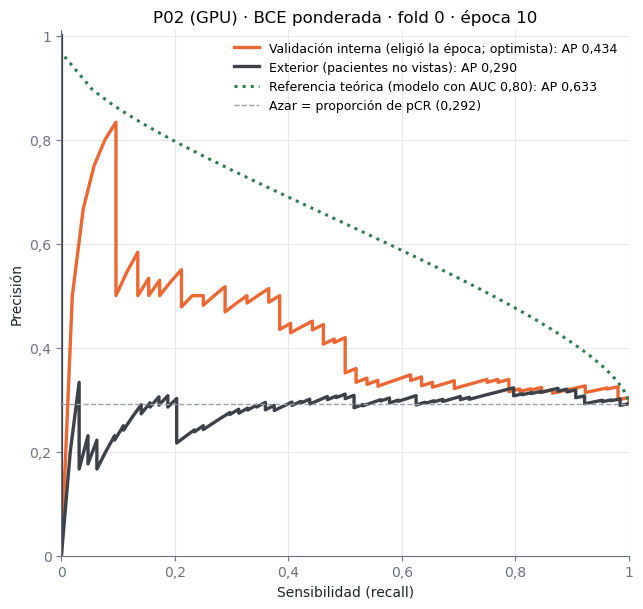

In [93]:
R.fig_pr_dos(R.P02_GPU, 'weighted', 0, 'P02 (GPU)')

In [94]:
R.tabla_umbrales(R.P02_GPU, 'weighted', 0)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,480",120,35,51,13,"0,203","0,774","0,271","0,489"
"0,325 (el de E57): 0,325",14,141,5,59,"0,922","0,090","0,295","0,506"
"0,5: 0,500",135,20,60,4,"0,062","0,871","0,167","0,467"


#### P02 (GPU) · BCE ponderada · fold 1 · 22 épocas · checkpoint de época 12

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [95]:
R.tabla_epocas(R.P02_GPU, 'weighted', 1)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.991192,0.696282,0.714049,0.588670,0.480149,0.587249,0.474232,"0,001",74
2,0.970099,0.623848,0.641321,0.568427,0.539547,0.568157,0.539273,"0,001",72
3,0.972767,0.682743,0.690686,0.551444,0.522333,0.552048,0.521356,"0,001",73
4,0.966844,0.649505,0.689412,0.545517,0.536445,0.545630,0.536877,"0,001",73
5,0.967204,0.648784,0.676358,0.592008,0.536135,0.593474,0.533164,"0,001",72
6,0.962826,0.632773,0.682870,0.544885,0.528846,0.545377,0.528658,"0,001",72
7,0.961591,0.630107,0.664188,0.544291,0.507909,0.544853,0.507792,"0,0005",73
8,0.955751,0.633627,0.685283,0.592796,0.583824,0.595302,0.582511,"0,0005",72
9,0.954926,0.634670,0.711998,0.599030,0.576303,0.599579,0.574251,"0,0005",73
10,0.946412,0.630312,0.719400,0.589079,0.570875,0.588877,0.571352,"0,0005",72


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

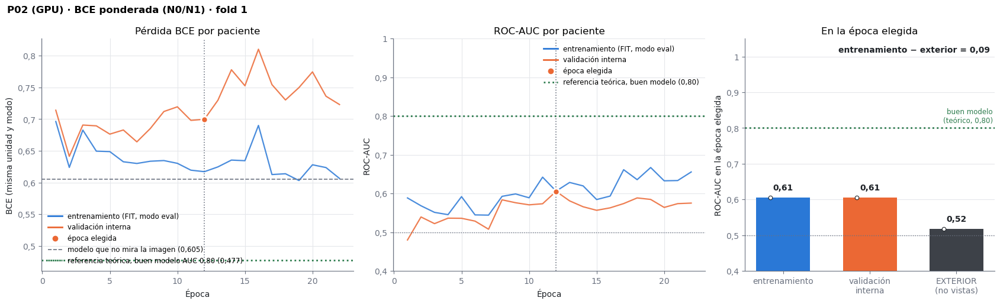

In [96]:
R.fig_tres(R.P02_GPU, 'weighted', 1, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

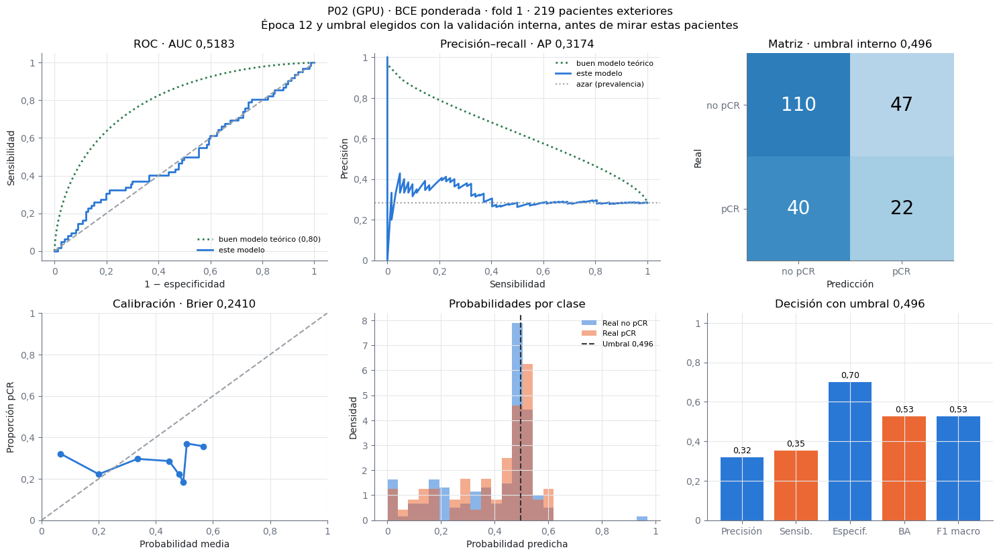

In [97]:
R.fig_resultados(R.P02_GPU, 'weighted', 1, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

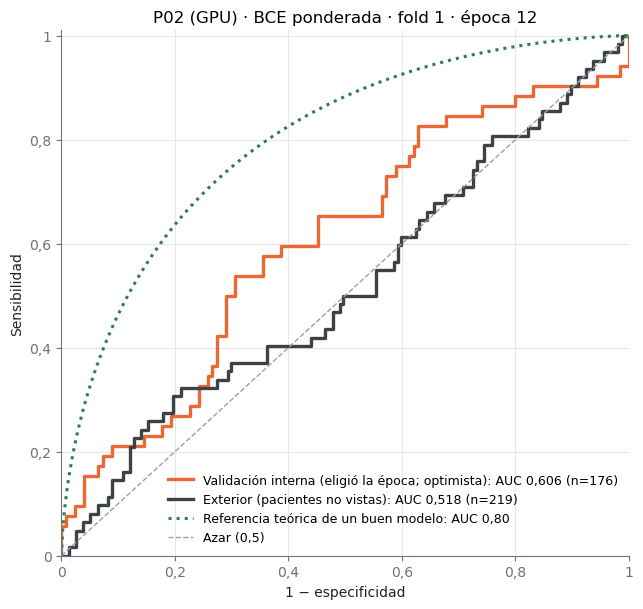

In [98]:
R.fig_roc_dos(R.P02_GPU, 'weighted', 1, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

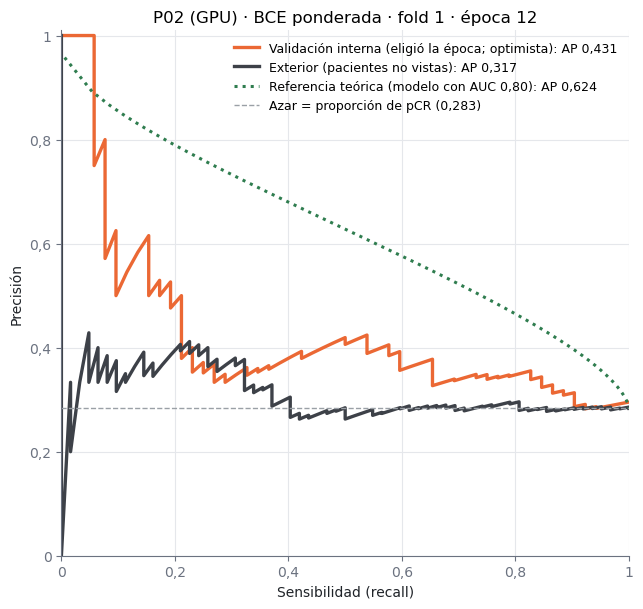

In [99]:
R.fig_pr_dos(R.P02_GPU, 'weighted', 1, 'P02 (GPU)')

In [100]:
R.tabla_umbrales(R.P02_GPU, 'weighted', 1)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,496",110,47,40,22,"0,355","0,701","0,319","0,528"
"0,325 (el de E57): 0,325",47,110,19,43,"0,694","0,299","0,281","0,496"
"0,5: 0,500",115,42,42,20,"0,323","0,732","0,323","0,528"


#### P02 (GPU) · BCE ponderada · fold 2 · 22 épocas · checkpoint de época 12

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [101]:
R.tabla_epocas(R.P02_GPU, 'weighted', 2)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.984047,0.690094,0.693490,0.553264,0.513729,0.550236,0.522170,"0,001",73
2,0.970862,0.669791,0.679778,0.550354,0.486271,0.550283,0.487399,"0,001",73
3,0.970453,0.659064,0.668873,0.541674,0.437030,0.539472,0.438670,"0,001",73
4,0.970062,0.688352,0.693800,0.534740,0.479675,0.532535,0.500272,"0,001",73
5,0.969486,0.683216,0.693607,0.551644,0.488418,0.552580,0.479064,"0,001",73
6,0.966343,0.692562,0.697814,0.539351,0.502684,0.536275,0.511830,"0,0005",72
7,0.965365,0.700383,0.705162,0.552701,0.499770,0.555703,0.489393,"0,0005",72
8,0.961603,0.659812,0.681801,0.594457,0.505292,0.592699,0.512569,"0,0005",72
9,0.965346,0.679717,0.696522,0.594065,0.530526,0.587265,0.536153,"0,0005",73
10,0.957694,0.662534,0.685111,0.584502,0.571560,0.582235,0.567560,"0,0005",73


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

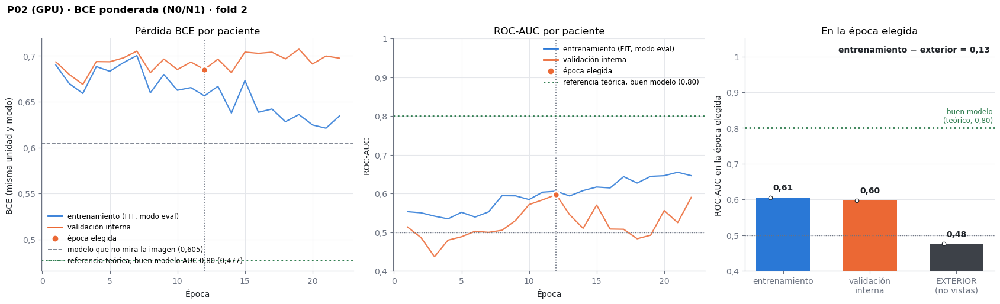

In [102]:
R.fig_tres(R.P02_GPU, 'weighted', 2, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

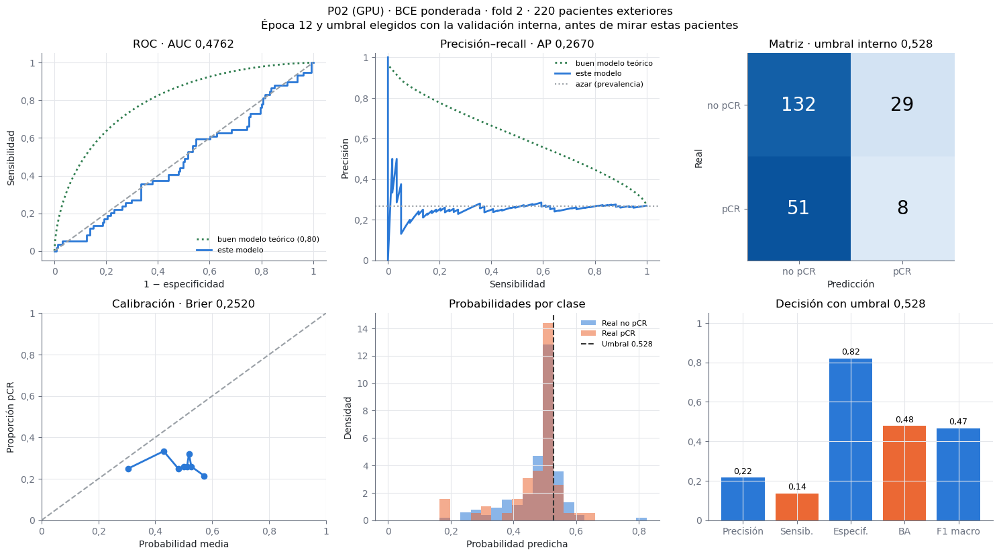

In [103]:
R.fig_resultados(R.P02_GPU, 'weighted', 2, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

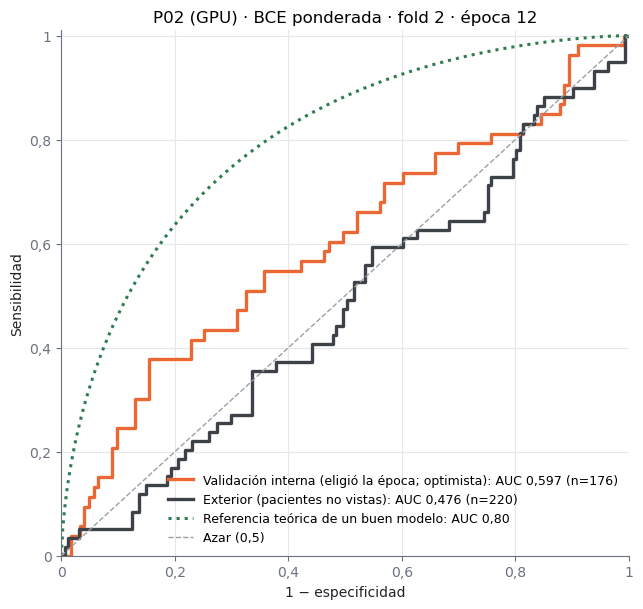

In [104]:
R.fig_roc_dos(R.P02_GPU, 'weighted', 2, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

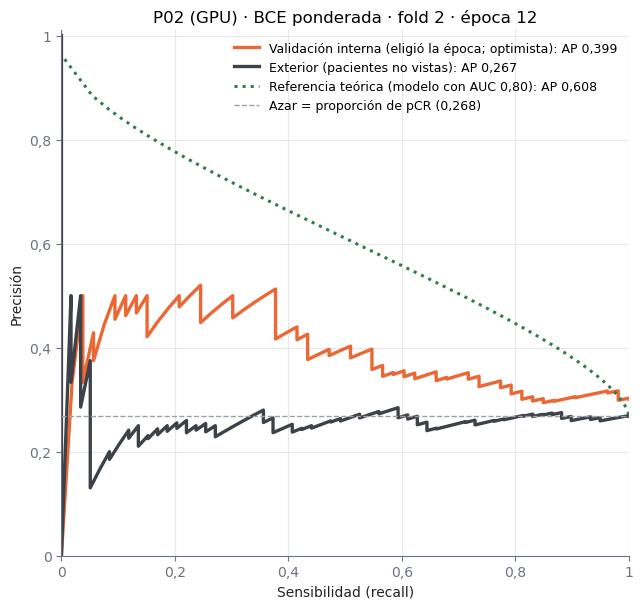

In [105]:
R.fig_pr_dos(R.P02_GPU, 'weighted', 2, 'P02 (GPU)')

In [106]:
R.tabla_umbrales(R.P02_GPU, 'weighted', 2)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,528",132,29,51,8,"0,136","0,820","0,216","0,478"
"0,325 (el de E57): 0,325",10,151,5,54,"0,915","0,062","0,263","0,489"
"0,5: 0,500",71,90,24,35,"0,593","0,441","0,280","0,517"


#### P02 (GPU) · BCE ponderada · fold 3 · 11 épocas · checkpoint de época 1

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [107]:
R.tabla_epocas(R.P02_GPU, 'weighted', 3)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,1.015174,0.663488,0.678267,0.596044,0.565556,0.591186,0.571561,"0,001",73
2,0.985459,0.619719,0.655743,0.597252,0.537619,0.594834,0.539511,"0,001",72
3,0.978642,0.619367,0.661550,0.634276,0.547302,0.629967,0.552779,"0,001",72
4,0.982197,0.660775,0.704538,0.636875,0.540635,0.633269,0.548160,"0,001",72
5,0.975847,0.641078,0.669181,0.637862,0.551429,0.634053,0.556776,"0,001",73
6,0.965929,0.659123,0.704674,0.653161,0.532063,0.648501,0.537314,"0,0005",72
7,0.962833,0.614604,0.678210,0.661953,0.526825,0.657454,0.530157,"0,0005",72
8,0.960560,0.612982,0.679010,0.662658,0.530794,0.657883,0.534853,"0,0005",72
9,0.955053,0.656521,0.693060,0.649152,0.527778,0.642298,0.530325,"0,0005",72
10,0.944297,0.621623,0.702896,0.698181,0.510476,0.690788,0.516914,"0,00025",72


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

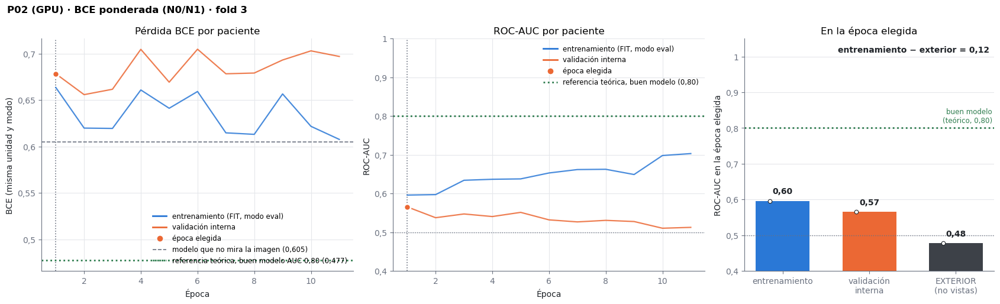

In [108]:
R.fig_tres(R.P02_GPU, 'weighted', 3, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

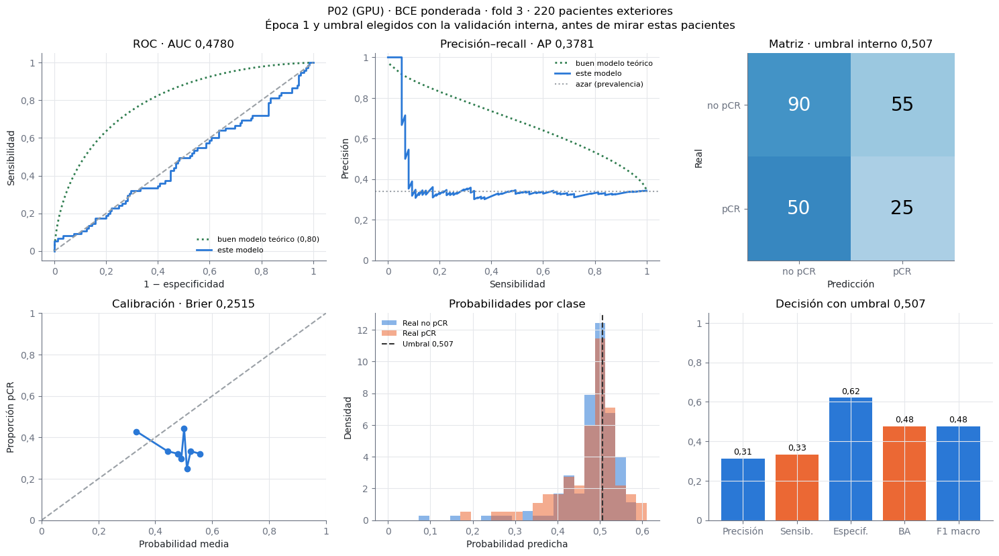

In [109]:
R.fig_resultados(R.P02_GPU, 'weighted', 3, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

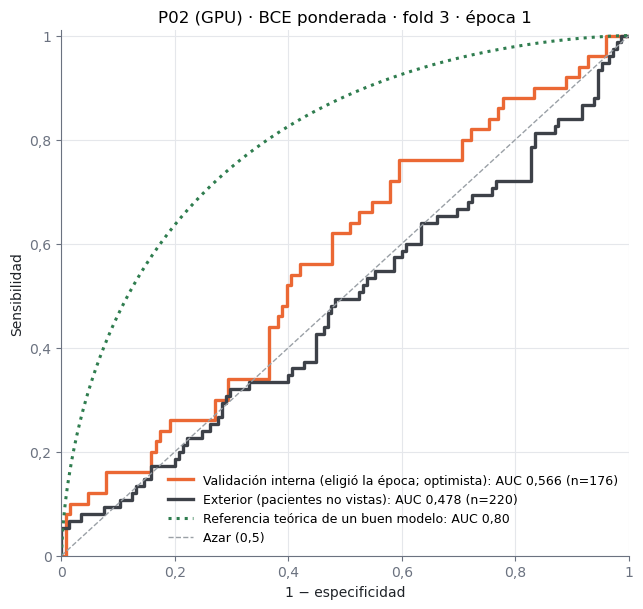

In [110]:
R.fig_roc_dos(R.P02_GPU, 'weighted', 3, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

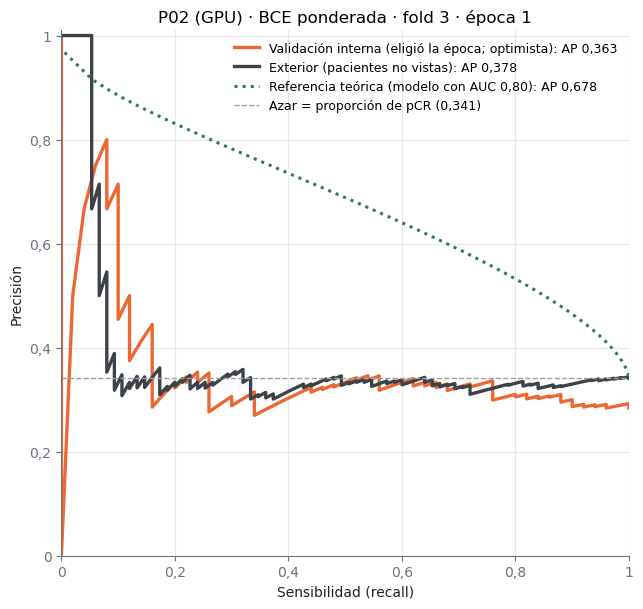

In [111]:
R.fig_pr_dos(R.P02_GPU, 'weighted', 3, 'P02 (GPU)')

In [112]:
R.tabla_umbrales(R.P02_GPU, 'weighted', 3)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,507",90,55,50,25,"0,333","0,621","0,312","0,477"
"0,325 (el de E57): 0,325",5,140,4,71,"0,947","0,034","0,336","0,491"
"0,5: 0,500",77,68,42,33,"0,440","0,531","0,327","0,486"


#### P02 (GPU) · BCE ponderada · fold 4 · 13 épocas · checkpoint de época 3

**Todas las épocas.** La fila resaltada es la que eligió la validación interna.

In [113]:
R.tabla_epocas(R.P02_GPU, 'weighted', 4)

Época,Pérdida train (online),BCE train (eval),BCE interna,AUC train (eval),AUC interna,AUC train por corte,AUC interna por corte,LR,Segundos
1,0.986065,0.695870,0.705915,0.585886,0.451148,0.583329,0.451619,"0,001",73
2,0.973226,0.678633,0.686830,0.578938,0.495502,0.575542,0.489478,"0,001",73
3,0.968613,0.672159,0.673627,0.591190,0.563120,0.589972,0.551295,"0,001",73
4,0.967590,0.697248,0.711254,0.604246,0.491393,0.604123,0.491068,"0,001",73
5,0.965772,0.656256,0.692259,0.602762,0.428505,0.600917,0.431785,"0,001",73
6,0.957213,0.648020,0.690551,0.619433,0.479839,0.616049,0.477323,"0,001",73
7,0.954801,0.607772,0.668591,0.581867,0.507289,0.580157,0.505509,"0,001",73
8,0.944707,0.653866,0.707152,0.655306,0.447115,0.650592,0.443034,"0,0005",73
9,0.939610,0.596843,0.682353,0.636893,0.504187,0.631258,0.500657,"0,0005",72
10,0.928969,0.597344,0.688052,0.622032,0.531638,0.618653,0.525103,"0,0005",72


**Curvas.** Train (azul) y validación interna (naranja) en el mismo modo de evaluación; a la derecha, el AUC de las tres particiones en la época elegida.

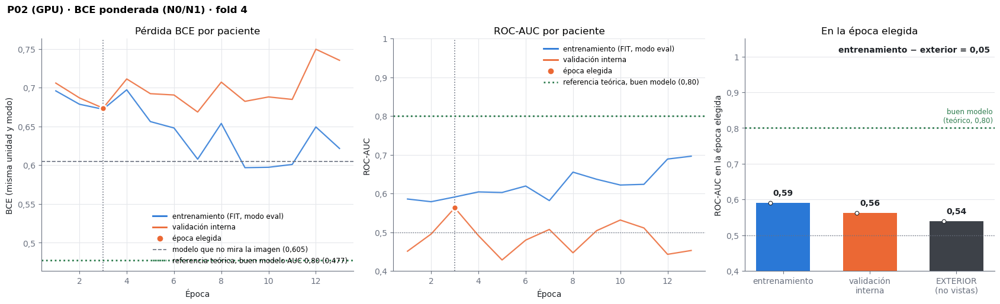

In [114]:
R.fig_tres(R.P02_GPU, 'weighted', 4, 'P02 (GPU)')

**Resultados sobre las pacientes exteriores** (las del fold, nunca vistas al entrenar ni al elegir).

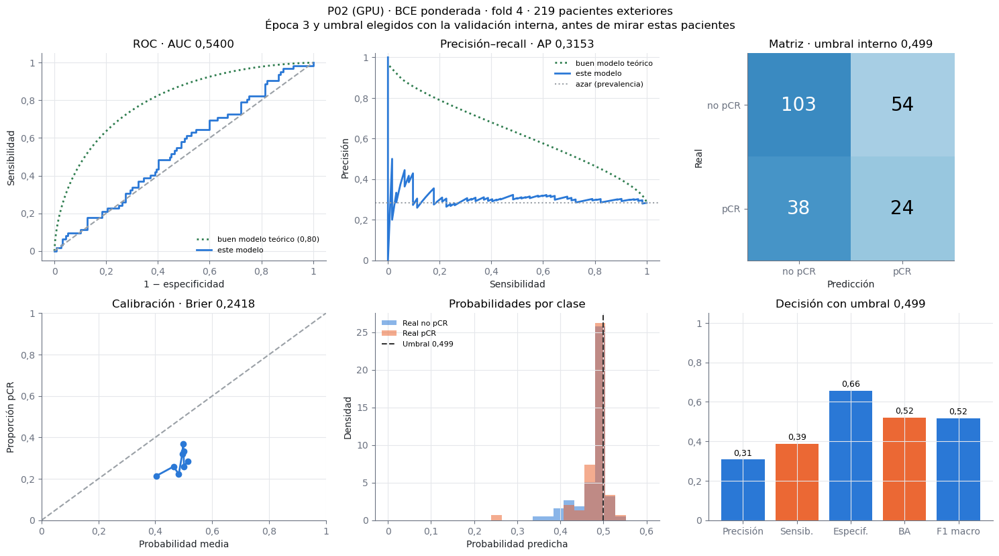

In [115]:
R.fig_resultados(R.P02_GPU, 'weighted', 4, 'P02 (GPU)')

**Curva ROC de la validación interna frente a la del exterior.** La interna es la que eligió la época, así que es optimista; la del exterior mide lo que pasa con pacientes nuevas. La línea verde punteada es una referencia teórica de un buen modelo (AUC 0,80), para comparar a simple vista; no es ningún modelo entrenado.

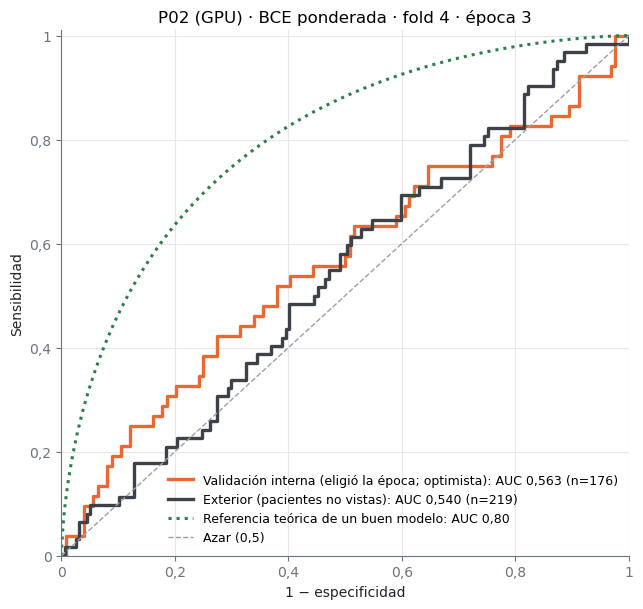

In [116]:
R.fig_roc_dos(R.P02_GPU, 'weighted', 4, 'P02 (GPU)')

**Precisión–recall, interna frente a exterior.** Aquí el azar no es 0,5 sino la proporción de pacientes con pCR (≈ 0,29): un modelo que adivinara acertaría en esa proporción al marcar a alguien como pCR.

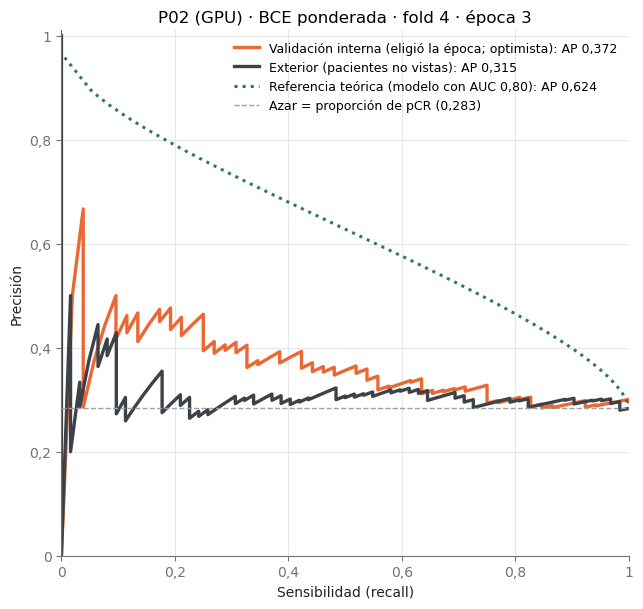

In [117]:
R.fig_pr_dos(R.P02_GPU, 'weighted', 4, 'P02 (GPU)')

In [118]:
R.tabla_umbrales(R.P02_GPU, 'weighted', 4)

Umbral,TN,FP,FN,TP,Sensibilidad,Especificidad,Precisión pCR,Balanced accuracy
"interno (elegido antes): 0,499",103,54,38,24,"0,387","0,656","0,308","0,522"
"0,325 (el de E57): 0,325",0,157,1,61,"0,984","0,000","0,280","0,492"
"0,5: 0,500",117,40,47,15,"0,242","0,745","0,273","0,494"


<a id="entrega"></a>
## 7. Modelo de entrega y test

Las reglas para elegir el modelo final se fijaron el 20 de octubre, antes de ver los resultados de la GPU, y se publicaron en GitHub (commit `830ccd2`) para que la fecha sea verificable: [REGLAS_ENTREGA.md](REGLAS_ENTREGA.md). En resumen: manda la AUC exterior conjunta; se elige BCE normal salvo que la ponderada sea claramente mejor; P02 sustituye a E57 si su AUC conjunta es al menos 0,55; se entrega el promedio de los 5 modelos con la mediana de los umbrales internos; y el test se evalúa una sola vez.

In [119]:
display(Markdown(R.entrega()))

**Entregable:** E57_original.

**Motivo:** IC95 pareado incluye 0: normal por defecto (regla 3); AUC conjunta 0.532 < 0.55: se mantiene E57 (regla 4).

El test todavía no se ha evaluado; se hará una sola vez, con el visto bueno del estudiante.

<a id="e57"></a>
## 8. E57 como referencia

E57 es la red con la que empezó esta etapa (descrita en la sección 1) entrenada con su receta original: lotes de 2 pacientes y sin aumento.

Sus cifras optimistas y honestas no son comparables entre sí. El detalle de sus 5 folds y del test está en [E57/RESULTADOS.ipynb](../E57/RESULTADOS.ipynb); la versión anterior de este notebook, con N01 completo, en [anteriores/RESULTADOS_N01.ipynb](anteriores/RESULTADOS_N01.ipynb).

In [120]:
R.tabla_e57()

Medida,AUC,Tipo
"Pico de validación, fold 0 (época 14 de 24)","0,670",optimista: época elegida en la misma validación
Media de los picos de 5 folds,"0,622",optimista
"Validación anidada de 5 folds (otra receta, 15/10)","0,527",honesta
"Test público, una evaluación (IC95 0,475–0,671)","0,573",honesta


<a id="despues"></a>
## 9. Qué más se probó después de P02

P02 apenas superó a la línea base de cohorte. Antes de entrenar nada más se pasaron filtros baratos sobre las imágenes de train (pasos 0, 0b y 0c), y después se probó si promediar semillas reducía el ruido. Cada hipótesis tiene su documento con el criterio escrito **antes** de calcular o entrenar; el SHA-256 de ese documento queda anotado en su `resumen.json`. Todas las comparaciones son pareadas sobre las 1.097 pacientes, con bootstrap estratificado por fold × cohorte × clase.

In [121]:
R.tabla_hipotesis()

,Hipótesis,Criterio fijado antes,Resultado,Decisión,Documento
0,Línea base de cohorte,Cuánto de P02 es saber de qué cohorte viene la...,"cohorte 0,523; P02 − cohorte +0,009 [-0,025, +...",Referencia,P03_PASO0.md
1,P03 · recorte central,Realce ≥ 60 % dentro del recorte en las 3 coho...,"solo cumple 192 px; razón periférica 0,37",Descartado,P03_PASO0.md
2,"P04 · realce relativo (PE, SER)",IC95 de cohorte + relativas − cohorte > 0,"+0,014 [-0,012, +0,039]",Descartado,P04_PASO0B.md
3,P06 · región que más realza,IC95 de cohorte + región − cohorte > 0,"+0,009 [-0,019, +0,038]",Descartado,P06_PASO0C.md
4,"P05 · tasa de aprendizaje 0,0001",IC95 de P05 − P02 > 0,no se ejecutó: ya probado en E12 y E55,Retirado,P05_LR_BAJO.md
5,P07 · ensemble de 3 semillas,IC95 de ensemble − semilla 42 > 0,"ensemble 0,543; +0,012 [-0,013, +0,036]",Descartado,P07_SEMILLAS.md


### P07 · ensemble de 3 semillas

La misma receta P02 normal entrenada con tres semillas por fold (15 modelos) y promediada. La semilla sola mueve el resultado ≈ 0,03; el ensemble queda por encima de la media de sus modelos, en la dirección prevista, pero la mejora frente a la semilla 42 no es demostrable. No se elige una semilla por su AUC exterior: sería seleccionar con la exterior.

In [122]:
R.tabla_p07()

Modelo,AUC exterior conjunta (1.097)
Ensemble (media de 3),"0,543"
"Semilla 42 (P02, GPU)","0,531"
Semilla 17 (Mac),"0,553"
Semilla 123 (Mac),"0,521"
Línea base de cohorte,"0,523"


<a id="n01cv"></a>
## 10. N01 en 5 folds: la receta de E57 con validación cruzada

E57 no tenía una validación cruzada limpia propia: su cifra honesta es el test. N01 es su receta (2 pacientes × 10 cortes por lote, sin aumento) con el protocolo FIT / interna / exterior; solo existía el fold 0 (exterior 0,617, la más alta del proyecto, con AUC de FIT 0,505). Se completaron los folds 1–4 para medirla en las 1.097 pacientes. No es candidata a entrega. Criterios en [N01_CV.md](N01_CV.md).

In [123]:
display(Markdown(R.n01_cv()))

**AUC exterior conjunta de N01 (1.097 pacientes):** 0,507; por corte 0,508.

**Por fold:** fold 0: 0,617, fold 1: 0,494, fold 2: 0,542, fold 3: 0,472, fold 4: 0,445.

**Frente a la línea base de cohorte (0,523):** -0,015 [-0,037, +0,006]. **Frente a P02 normal (0,531):** -0,024 [-0,058, +0,009].

**¿Aprende señal más allá de la cohorte?** No (criterio: IC95 frente a la cohorte por encima de 0).

Dentro de cada cohorte: Duke 0,460, I-SPY1 0,501, I-SPY2 0,513.

## Cómo leer estos resultados

El AUC mide si el modelo ordena bien a las pacientes y no depende del umbral; la matriz de confusión sí depende de él. La pregunta de la etapa no ha sido qué arquitectura es mejor, sino si la red aprendía: con la receta de E57 apenas lo hacía; con 10 pacientes por lote aprende; con aumento sincronizado memoriza menos. Cuánto de eso se generaliza a pacientes nuevas lo dice la validación cruzada de la sección 6 y, al final, una única evaluación en test.

Uso educativo, sin validez clínica.